# Predicting how temperature shifts code ideas — claim L (iteration 8)

**Is temperature really an LLM's "creativity knob"?** When the sampling temperature goes up, does a code model invent *new* algorithms, or does it only re-weight a couple of ideas it already holds? This artifact answers with a **pre-registered, hash-chained prediction** of how temperature changes *which algorithm* a model writes.

**Method (claim L)**
1. **Blind decision-token location.** For each unit (model × task), 6 programs sampled at T = 1 are cut at every prefix length *k*. Eight continuations are sampled from each cut and labelled with the algorithm they end up implementing. A Bayesian change-point rule finds the position where that label distribution jumps. There sits the **decision token**, where the model commits to an algorithm, e.g. `' Kr'` (Kruskal) vs `' Prim'` at generated token 61 of the minimum-spanning-tree task.
2. **Forced tokens.** Each of the top-20 tokens at that position is forced, and its continuations are labelled. This gives $\hat P(A \mid t)$, the algorithm distribution after token *t*. A **second decision** inside a branch is searched the same way when the first one leaves that branch mixed.
3. **The frozen law.** Teacher-forced logits along each opening give, for every temperature *T* and sampler (top-p 1 or top-k 10), the probability of staying on the opening and of each decision token. Composed with $\hat P$, they predict the algorithm shares $P_T(A)$ **before any temperature sample is drawn**. The predictions were committed to a hash chain (COMMIT #2).
4. **Sweep and score.** For each cell, 100 *same-stream* program slots (5 prompt templates × 20 slots; a slot reuses one uniform stream at every temperature) are sampled at T = 0.3 / 0.7 / 1.0 / 1.3 × {top-p 1, top-k 10} and labelled. The law is scored by MAE, the mean over T of the total-variation distance between predicted and observed shares. Rivals: B0 flat shares; B1 algorithm-level tempering $q^{1/T}$; B2 the single-decision law; BH the same law placed at the highest-entropy position.

**Units.** Qwen3-8B: A3 trapped rain water, B6 valid anagram, B3 MST weight (used to develop the law). gemma-3-4b-it: G-T04 substring search, G-R6 first/last position (held out). Llama-3.1-8B-Instruct: L-T1 grid path (held out). L-T1's BFS-vs-DFS split is the "*does the LLM always design BFS?*" question.

**Artifact result.** Claim L is **PARTIAL**. 5/6 units pass (MAE ≤ 0.10 and H ≤ 0.3 bits): A3 0.029, B6 0.054, B3 0.043, G-T04 0.033, G-R6 0.014. L-T1 fails at 0.142. Only 3 held-out units were scored, fewer than the 4 the plan requires. None of the 4,703 correct programs was a novel algorithm. Tight T gives about 1 idea written in 1–4 phrasings. Loosening T moves mass to the second known idea at the predicted rate and multiplies its phrasings, but **never adds ideas**.

### What this notebook runs
`method.py` drives 15 stages. The GPU stages need 4–8 B-parameter models on a ≥ 20 GB GPU (about 5 h), and the judge stages call LLM APIs. Neither fits a 10-minute Colab session. `mini_demo_data.json` therefore carries what those stages **stored**: the locator's label counts, the forced-token counts, the compact teacher-forced quantities, the per-slot replays and the labelled sweep programs. The notebook re-runs **every CPU computation that turns them into the claim, using the artifact's own code**:

| `method.py` stage | what runs here |
|---|---|
| `cputests` | law unit tests U5, U8, U9, U10, U11 and the change-point rule's self-test |
| `gemma` / `llama` / `qwen` → locate | change-point detection on the stored label series, decision-token classes and H(A \| classes) from the stored forced-token counts |
| `gemma` / `llama` / `qwen` → predict | the law L and the rivals B0/B1/B2/BH from the stored teacher-forced quantities, replay-implied shares |
| `analysis` | the committed scoring: MAE, McNemar drop test, replay accuracy, bootstrap CIs, placebos, phrasing clusters, verdict |
| `figures` | F1 locator curves, F2 decision tokens, F3 predicted vs observed, F4 calibration, F6 replay |

Each `src/` module appears in its own cell, copied from the artifact. Edits are marked `# notebook:`.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (cfg8 and analysis_L log through it)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib — pre-installed on Colab, install locally only (at Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
# Import block of method.py (the entry point), as in the original
import os
import subprocess
import sys
from pathlib import Path

# Imports used by the driver cells below (every src/ module cell also keeps its own original imports)
import json
import math
import time
import types
from collections import Counter
from typing import Any

import numpy as np
from loguru import logger

# Notebook additions: inline figures and the %%module cell magic
import matplotlib.pyplot as plt
from IPython.core.magic import register_cell_magic


@register_cell_magic
def module(line, cell):
    """%%module <name>: run the cell as if it were the artifact's file src/<name>.py and register it in sys.modules,
    so `import <name>` (in later cells and inside other modules) behaves exactly as in the original src/ layout.
    Every module keeps its own namespace: e.g. predict.cell_prediction and predict8.cell_prediction stay distinct."""
    name = line.strip()
    mod = types.ModuleType(name)
    mod.__file__ = f"src/{name}.py"
    sys.modules[name] = mod
    exec(compile(cell, mod.__file__, "exec"), mod.__dict__)

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-8/experiment-43/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
EX = {e["unit"]: e for e in data["examples"]}          # one example per scored unit (model x task)
print(data["metadata"]["title"])
print(data["metadata"]["example_granularity"])
for u, e in EX.items():
    print(f"  {u:6s} {e['model_id']:34s} held-out={str(e['held_out']):5s} {len(e['rows'])} labelled programs, "
          f"algorithm bins {e['locate']['bins']}")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Predicting how temperature shifts code ideas (claim L, iteration 8) - demo data
one example = one scored unit (model x task) with its committed law inputs and its 100 same-stream sweep slots (5 templates x 20 slots) at 4 temperatures and 2 samplers
  A3     Qwen/Qwen3-8B                      held-out=False 800 labelled programs, algorithm bins ['two_pointers', 'prefix_suffix_max', 'monotonic_stack', 'peak_split', 'other', 'invalid']
  B6     Qwen/Qwen3-8B                      held-out=False 800 labelled programs, algorithm bins ['sort_compare', 'hash_count', 'fixed_count_array', 'other', 'invalid']
  B3     Qwen/Qwen3-8B                      held-out=False 800 labelled programs, algorithm bins ['kruskal', 'prim_heap', 'prim_array', 'boruvka', 'other', 'invalid']
  G-T04  google/gemma-3-4b-it               held-out=True  800 labelled programs, algorithm bins ['naive', 'kmp', 'rabin_karp', 'z_algorithm', 

## Configuration
All tunable sizes of the CPU stages are set here. They are the **artifact's own values**. With all six units, the scoring reproduces `results/analysis_L.json`: every count, MAE, test and verdict exactly, and the resampled CIs to within 1e-17. The whole notebook runs in well under a minute on a CPU. The comments give the minimum configuration (one unit, about 1% of every resampling size), which was the first configuration tested and produces every output in a few seconds.

In [5]:
# Scaling log (clean Colab-like venv, whole notebook incl. pip installs): minimum config below 18 s;
# 3 units (B3, G-R6, L-T1) at ~10% resampling sizes 15 s; the artifact's full config (these values) ~20 s.

# Which scored units to run: all six scored units, in cfg8.UNITS order (as the artifact)
UNITS_TO_RUN = ["A3", "B6", "B3", "G-T04", "G-R6", "L-T1"]   # minimum tested: ["G-R6"]

# analysis_L (scoring): resampling sizes (artifact values)
N_BOOT = 1000             # minimum tested: 10   slot-bootstrap replicates of MAE(L) - MAE(rival)         (analysis 7.6)
N_DROP_PLACEBO = 500      # minimum tested: 10   temperature-label shuffles in the placebo of the drop test (analysis 7.3)
N_TOKEN_MAP_PLACEBO = 200 # minimum tested: 10   Phat-row shuffles in the token-map placebo                (analysis 7.7)
N_HILL1_REP = 200         # minimum tested: 10   rarefaction replicates of the correct-only Hill-1 diversity

# locate (CPU half): bootstrap of the decision-class entropy CI (artifact value)
N_H_BOOT = 300            # minimum tested: 10

# cputests: synthetic test sizes (artifact values)
U10_N = 1000              # minimum tested: 10   synthetic programs in U10 (top-k shadow == direct top-k)
U11_N_U = 10000           # minimum tested: 100  uniform vectors in U11 (replay walk == analytic opening probability)
CP_SELFTEST_N = 200       # minimum tested: 10   null series and planted-jump series in the change-point self-test

## The entry point: `method.py`
`method.py` only orchestrates. Each stage launches a script from `src/` as a subprocess, in the order below, and every stage resumes from its result files. The code is unchanged except that `main()` is **not called**. The loop at the end prints the stage plan and marks the stages whose CPU computations this notebook replays.

In [6]:
"""Predicting how temperature shifts code ideas (iteration 8, claim L): entry point.

Runs every stage in order (each stage resumes from its result files; commits refuse to overwrite):
  vendor      copy the prior artifacts' files into inputs/ with sha256 (src/vendor_inputs.py)
  prompts     prompt ids per (unit, template) with source checks (src/prompts8.py)
  cputests    U5/U8/U9/U10/U11, change-point rule, scoring dry run on iteration-7 data, labeller references
  commit0     protocol8L.json + code hashes, COMMIT #0 (src/commit0.py)
  gemma       held-out family 1: tests, fit (+ engine check), locate, COMMIT #1, predict, COMMIT #2, sweep
  llama       held-out family 2: the same plus bench-candidate selection (COMMIT #1a) and label re-gate (COMMIT #1b)
  qwen        law-development family: A3, B6 (second decisions), B3 (fresh streams)
  base        base sub-arm: Qwen3-8B and Qwen3-8B-Base teacher forcing, then analysis (src/base_arm.py)
  adjudicate  judges on cells with > 20% 'other' (src/novelty8.py adjudicate)
  analysis    committed scoring (src/analysis_L.py) -> results/analysis_L.json, results/verdict.json
  novelty     novelty audit of every correct off-catalogue program (src/novelty8.py audit)
  figures     F1-F6 (src/figures8.py)
  report      results/summary.md (src/report8.py)
  outputs     method_out.json (src/outputs8.py)
  rederive    audit/rederive.py (standard library only)
Usage: .venv/bin/python method.py all | <stage>[,<stage>...]
"""

ROOT = Path.cwd()   # notebook: was Path(__file__).resolve().parent (a notebook has no __file__)
SRC = ROOT / "src"
PY = sys.executable
GPU_STAGES = "tests,fit,locate,commit1,predict,commit2,sweep"

STAGES = {
    "vendor": [[PY, "vendor_inputs.py"]],
    "prompts": [[PY, "prompts8.py"]],
    "cputests": [[PY, "tests_cpu.py"]],
    "commit0": [[PY, "commit0.py"]],
    "gemma": [[PY, "gpu8.py", "gemma", GPU_STAGES]],
    "llama": [[PY, "gpu8.py", "llama", GPU_STAGES]],
    "qwen": [[PY, "gpu8.py", "qwen", GPU_STAGES]],
    "base": [[PY, "base_arm.py", "gpu", "qwen"], [PY, "base_arm.py", "gpu", "qwen_base"], [PY, "base_arm.py", "analyze"]],
    "adjudicate": [[PY, "novelty8.py", "adjudicate"]],
    "analysis": [[PY, "analysis_L.py"]],
    "novelty": [[PY, "novelty8.py", "audit"]],
    "figures": [[PY, "figures8.py"]],
    "report": [[PY, "report8.py"]],
    "outputs": [[PY, "outputs8.py"]],
    "rederive": [[PY, "-I", str(ROOT / "audit" / "rederive.py")]],
}
ORDER = list(STAGES)


def main() -> None:
    want = ORDER if len(sys.argv) < 2 or sys.argv[1] == "all" else sys.argv[1].split(",")
    env = dict(os.environ, PYTORCH_CUDA_ALLOC_CONF="expandable_segments:True")
    for st in want:
        for cmd in STAGES[st]:
            print(f"== {st}: {' '.join(cmd[1:])}", flush=True)
            r = subprocess.run(cmd, cwd=str(SRC), env=env)
            if r.returncode != 0:
                raise SystemExit(f"stage {st} failed ({r.returncode})")


# notebook: main() is not called. Every stage runs a src/ script as a subprocess, and the GPU stages need a >= 20 GB GPU
# with Qwen3-8B, Qwen3-8B-Base, gemma-3-4b-it and Llama-3.1-8B-Instruct. The CPU half of the stages marked below is
# re-run in this notebook from the stored GPU outputs in mini_demo_data.json.
REPLAYED_HERE = {"cputests": "law unit tests + change-point self-test",
                 "gemma": "locate + predict, CPU half (G-T04, G-R6)",
                 "llama": "locate + predict, CPU half (L-T1)",
                 "qwen": "locate + predict, CPU half (A3, B6, B3)",
                 "analysis": "the committed scoring + verdict",
                 "figures": "F1-F4, F6 inline"}
for st in ORDER:
    cmd = " ; ".join(" ".join(c[1:]) for c in STAGES[st]).replace(str(ROOT) + "/", "")
    print(f"{st:<11}{cmd[:60]:<62}{'replayed: ' + REPLAYED_HERE[st] if st in REPLAYED_HERE else ''}")

vendor     vendor_inputs.py                                              
prompts    prompts8.py                                                   
cputests   tests_cpu.py                                                  replayed: law unit tests + change-point self-test
commit0    commit0.py                                                    
gemma      gpu8.py gemma tests,fit,locate,commit1,predict,commit2,sweep  replayed: locate + predict, CPU half (G-T04, G-R6)
llama      gpu8.py llama tests,fit,locate,commit1,predict,commit2,sweep  replayed: locate + predict, CPU half (L-T1)
qwen       gpu8.py qwen tests,fit,locate,commit1,predict,commit2,sweep   replayed: locate + predict, CPU half (A3, B6, B3)
base       base_arm.py gpu qwen ; base_arm.py gpu qwen_base ; base_arm.  
adjudicate novelty8.py adjudicate                                        
analysis   analysis_L.py                                                 replayed: the committed scoring + verdict
novelty    novelty8.py audit

## Shared constants: `src/cfg8.py`
The units, temperatures, samplers and pre-registered thresholds (`THRESH`) that every stage imports. This cell holds the subset of `cfg8.py` that the CPU stages use, copied verbatim. Left out: the run-volume paths of the prior artifacts and the hashing, timing and RAM-limit helpers. The `%%module` magic runs the cell as the module `cfg8`, so the other modules' `from cfg8 import ...` lines work unchanged.

In [7]:
%%module cfg8
#!/usr/bin/env python3
"""Iteration-8 claim L constants: a frozen two-decision temperature law for algorithm choice, scored on 8 units in
three model families (Qwen3-8B, gemma-3-4b-it, Llama-3.1-8B-Instruct), plus a base-vs-instruct sub-arm (Qwen3-8B-Base).

Conventions (inherited from iterations 4-7):
- CRN: every program slot draws one uniform per generated token from u_stream(key) = PCG64(seed(key)); the sampler
  (iteration-6 engine5 transform) is fp64 softmax(logits / T) -> top-k mask (keep p >= k-th largest) -> cumsum over the
  FULL vocabulary in TOKEN-ID order, normalised by the kept mass -> searchsorted(u). Generated step t uses u[t].
- FIT keys reuse the source artifacts' keys so the fit twins double as engine checks: Qwen ('iter7T', unit, w, slot)
  (art_MZAfDPVhM6Ui cfg7), Gemma ('iter5E' | 'iter6S', task, w, slot) (art_zNyBP6zieI5u cfg), Llama new
  ('iter8L-fit', ...). New namespaces: seed8(ns, model, unit, template, slot) = int(first 16 hex of sha256('|'.join)).
- Decision position d = number of generated tokens before the decision token (the decision token is generated at
  step d with u[d]); the opening O_c is the d tokens before it.
"""

from __future__ import annotations

import hashlib
import json
import math
import os
import resource
import sys
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Iterable

import numpy as np
from loguru import logger

ROOT = Path.cwd()   # notebook: was Path(__file__).resolve().parents[1] (the artifact folder)
SRC = ROOT / "src"
INPUTS = ROOT / "inputs"
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"
LOG_DIR = ROOT / "logs"
PRED_DIR = ROOT / "predictions"
CACHE_DIR = ROOT / "cache"
# notebook: the original creates these folders here; the notebook neither reads nor writes them

COMMITS = ROOT / "commitments.log"
SAMPLES_RAW = DATA_DIR / "samples_raw.jsonl"      # every program of every arm (fit twins, sweep, top-k shadow)
LABELS = DATA_DIR / "labels.jsonl"
CONTS = DATA_DIR / "continuations.jsonl"          # locator / refinement / forced-token continuations
CONT_LABELS = DATA_DIR / "continuation_labels.jsonl"
TIMING = RESULTS_DIR / "timing.jsonl"

# notebook: the run-volume paths of the prior artifacts (SRCS, ART_J3RM_DIR) are not needed here

# ------------------------------------------------------------------------------------------------ models
FAMILIES: dict[str, dict[str, Any]] = {
    "gemma": {"model_id": "google/gemma-3-4b-it", "rev": "093f9f388b31de276ce2de164bdc2081324b9767",
              "stop_ids": (1, 106), "pad_id": 106},
    "llama": {"model_id": "meta-llama/Llama-3.1-8B-Instruct", "rev": "0e9e39f249a16976918f6564b8830bc894c89659",
              "stop_ids": (128001, 128008, 128009), "pad_id": 128009},
    "qwen": {"model_id": "Qwen/Qwen3-8B", "rev": "b968826d9c46dd6066d109eabc6255188de91218",
             "stop_ids": (151645, 151643), "pad_id": 151645},
    "qwen_base": {"model_id": "Qwen/Qwen3-8B-Base", "rev": "49e3418fbbbca6ecbdf9608b4d22e5a407081db4",
                  "stop_ids": (151645, 151643), "pad_id": 151643},
}
FAMILY_ORDER = ("gemma", "llama", "qwen")          # held-out families first
PRECISION = "bf16"
U_LEN = 2048

# ------------------------------------------------------------------------------------------------ units
TEMPLATES = ("W1", "W2", "W3", "W4", "W5")
LLAMA_BENCH_ORDER = ("T03", "T06", "T04", "R1", "T14", "T10", "T08")   # ITER2 exp11 pilot, most mixed first
LLAMA_BENCH_KEEP = 2
LLAMA_MINORITY_BAR = 0.10

UNITS: dict[str, dict[str, Any]] = {
    # law-development units (Qwen3-8B; iteration-7 law units), fit keys = iteration-7 twin keys
    "A3": {"family": "qwen", "task": "A3", "lab": "a", "held_out": False, "max_new": 640, "batch": 20,
           "catalogue": ["two_pointers", "prefix_suffix_max", "monotonic_stack", "peak_split"],
           "name": "trapped rain water", "fence": "bench"},
    "B6": {"family": "qwen", "task": "B6", "lab": "b", "held_out": False, "max_new": 384, "batch": 20,
           "catalogue": ["sort_compare", "hash_count", "fixed_count_array"], "name": "valid anagram",
           "fence": "bench"},
    "B3": {"family": "qwen", "task": "B3", "lab": "b", "held_out": False, "max_new": 768, "batch": 20,
           "catalogue": ["kruskal", "prim_heap", "prim_array", "boruvka"], "name": "minimum spanning tree weight",
           "fence": "bench"},
    # held-out units (never used to develop the law or its procedure)
    "G-T04": {"family": "gemma", "task": "T04", "lab": "bench", "held_out": True, "max_new": 1024, "batch": 20,
              "catalogue": ["naive", "kmp", "rabin_karp", "z_algorithm", "bmh", "builtin"],
              "name": "substring search", "fence": "bench"},
    "G-R6": {"family": "gemma", "task": "R6", "lab": "bench", "held_out": True, "max_new": 1024, "batch": 20,
             "catalogue": ["binary_search", "bisect_module", "exponential_search", "linear_scan"],
             "name": "first and last position", "fence": "bench"},
    "L-T1": {"family": "llama", "task": "T1", "lab": "path", "held_out": True, "max_new": 1536, "batch": 10,
             "catalogue": ["bfs", "dfs", "bibfs", "astar_gbfs", "dijkstra", "iddfs"], "name": "grid path",
             "fence": "path"},
}
for _t in LLAMA_BENCH_ORDER:
    UNITS[f"L-{_t}"] = {"family": "llama", "task": _t, "lab": "bench", "held_out": True, "max_new": 1024,
                        "batch": 20, "catalogue": None, "name": f"bench {_t}", "fence": "bench", "candidate": True}
LAW_UNITS_FIXED = ("G-T04", "G-R6", "L-T1", "A3", "B6", "B3")

# ------------------------------------------------------------------------------------------------ design
TEMPS = (0.3, 0.7, 1.0, 1.3)
SAMPLERS = {"p1": 0, "k10": 10}
FIT_SLOTS = tuple(range(0, 20))       # x 5 templates = N 100 at T 1 (FIT keys)
SWEEP_SLOTS = tuple(range(0, 20))     # x 5 templates = N 100 per cell ('iter8L-sweep' keys)
NS_FIT_L = "iter8L-fit"
NS_LOC = "iter8L-loc"
NS_FORCE = "iter8L-force"
NS_SWEEP = "iter8L-sweep"
NS_REFINE = "iter8L-refine"
NS_SECOND = "iter8L-second"
N_LOC = 8                 # continuations per (path, k)
N_REFINE = 16
N_FORCE = 10              # per forced token (2 per template)
TOPN_FORCE = 20
TOPN_FORCE2 = 10
N_BASE_PATHS = 6
GRID_DENSE = tuple(range(0, 63, 2))
GRID_STEP_LATE = 4
W_MAX = 160
SECOND_SPAN = 24
BOOT_SEED = 20261023
N_BOOT = 1000
BUDGET_MSG = "AI Inventor per-run OpenRouter budget"
JUDGE_CAP_USD = 0.60

THRESH = {
    "unit_mae_pass": 0.10, "unit_H_bits_pass": 0.3, "claim_frac_pass": 0.70, "heldout_pass_min": 3,
    "heldout_scored_min": 4, "disconfirm_mae": 0.20, "disconfirm_heldout_n": 3,
    "cp_pchange": 0.9, "cp_tv": 0.25, "refine_tv": 0.25, "class_phat_min": 0.7, "class_mass_min": 0.02,
    "second_trigger_mass": 0.05, "second_trigger_H": 0.3, "cluster_cov": 0.20, "max_clusters": 4,
    "oc_agree": 0.95, "consistency_tvd": 0.10, "calib_fisher_p": 0.05, "engine_agree": 0.95, "shadow_ident": 0.95,
    "regate_agree": 0.9, "other_adjudicate": 0.20, "base_margin_gain": 2.0, "base_phrasing_dH": 0.5,
}


# ------------------------------------------------------------------------------------------------ utils
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    # notebook: the original also adds a rotating file sink LOG_DIR/<name>.log


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def stable_seed(*parts: Any) -> int:
    """Iteration 4-7 seed: int(sha256('|'.join(parts))) mod 2^63 (used for every FIT key reused from a source)."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


def seed8(*parts: Any) -> int:
    """Iteration-8 seed: first 16 hex digits of sha256('|'.join(parts)) (new namespaces only)."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest()[:16], 16)


def u_from_seed(seed: int, n: int = U_LEN) -> np.ndarray:
    return np.random.Generator(np.random.PCG64(seed)).random(n)


def fit_seed(unit: str, w: str, slot: int) -> int:
    """FIT keys: the source artifact's twin keys (Qwen: iteration 7; Gemma: exp31); Llama: a new namespace."""
    u = UNITS[unit]
    fam = u["family"]
    if fam == "qwen":
        return stable_seed("iter7T", unit, w, slot)
    if fam == "gemma":
        return stable_seed("iter5E" if slot < 10 else "iter6S", u["task"], w, slot)
    return seed8(NS_FIT_L, FAMILIES[fam]["model_id"], unit, w, slot)


def sweep_seed(unit: str, w: str, slot: int) -> int:
    return seed8(NS_SWEEP, FAMILIES[UNITS[unit]["family"]]["model_id"], unit, w, slot)


def _json_default(o: Any) -> Any:
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def write_json(p: Path, obj: Any) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=1, default=_json_default))
    tmp.replace(p)


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    with open(p) as fh:
        for line in fh:
            line = line.strip()
            if line:
                try:
                    out.append(json.loads(line))
                except json.JSONDecodeError:
                    logger.warning(f"skipping malformed line in {p.name}")
    return out

## The sampler and the law
### `src/replay.py`: one sampling step, re-implemented in float64
Every program token is `the first index where cumsum(p) >= u`. The cumulative sum runs in **token-id order**, and *u* is one pre-drawn uniform per position. Each slot owns **one** uniform stream that is reused at every temperature (common random numbers). The 4 temperatures × 2 samplers of a slot therefore differ only through the tempered logits. This *same-stream* design lets the analysis pair slots across temperatures (McNemar test) and replay single slots through the decision tokens.

In [8]:
%%module replay
#!/usr/bin/env python3
"""replay.pick(z, u, T, k): an independent float64 numpy re-implementation of the engine's per-step transform
(engine5.step_probs5 + engine_v4._inverse_cdf):
    p = softmax(z / T)                          (float64; z = the bf16 logits widened to float64)
    top-k: p[p < k-th largest p] = 0             (ties at the k-th value kept, exactly as the engine)
    cdf = cumsum(p) in TOKEN-ID order; cdf /= cdf[-1]
    token = first index with cdf >= u            (torch.searchsorted, right=False), clamped to V - 1
The token-id order makes the coupling across temperatures exact in marginals but NOT monotone in T, so per-slot
predictions must use pick(), never a sorted CDF.
"""

from __future__ import annotations

import numpy as np


def probs(z: np.ndarray, T: float, k: int = 0) -> np.ndarray:
    x = np.asarray(z, dtype=np.float64) / float(T)
    x = x - x.max()
    p = np.exp(x)
    p /= p.sum()
    if k and k > 0:
        kth = np.partition(p, -k)[-k]
        p = np.where(p < kth, 0.0, p)
    return p


def pick(z: np.ndarray, u: float, T: float, k: int = 0) -> int:
    p = probs(z, T, k)
    cdf = np.cumsum(p)
    cdf = cdf / cdf[-1]
    t = int(np.searchsorted(cdf, u, side="left"))
    return min(t, len(p) - 1)


def dist(z: np.ndarray, T: float, k: int = 0) -> np.ndarray:
    """The normalised sampling distribution of one step (kept mass renormalised)."""
    p = probs(z, T, k)
    return p / p.sum()

### `src/predict.py`: the iteration-7 prediction functions (imported unchanged by `predict8`)
Consider one decision ("fork") after a fixed opening *O*. The probability of staying on the opening is $w_T(O) = \prod_i \pi_T(o_i \mid o_{<i})$. The fork then mixes the per-token algorithm tables $\hat P(A \mid t)$ with weights $\pi_T(t)$. For a binary fork with margin *m* nats, the minority share is $1/(1 + e^{m/T})$. Unit tests: **U5**, a synthetic fork with margin 0.575 nats, plus a minority token at rank 11 that top-k 10 removes; **U8**, a path probability.

In [9]:
%%module predict
#!/usr/bin/env python3
"""Committed prediction functions (Part D4/D5), pure numpy over teacher-forced fp32 logits.

  pi_{T,kappa}(t | prefix) = softmax(z / T) over all tokens (kappa = full) or over the 10 largest logits (top10)
  w_{T,kappa}(c)   = prod_i pi_{T,kappa}(o_{c,i} | o_{c,<i})                       (probability of staying on O_c)
  F_{T,kappa}(c,A) = sum_t pi_{T,kappa}(t | O_c) Phat(A | O_c + t) + residual mass x Phat(A | residual bin)
  Phat_{T,kappa}(A) = sum_c w(c) F(c, A) + (1 - sum_c w(c)) q_rest(A)
Phat(A | t) is estimated from T = 1 continuations (the one-token concentration assumption carries it to other T).
"""

from __future__ import annotations

import math
from typing import Any

import numpy as np

import replay


def dist(z: np.ndarray, T: float, k: int) -> np.ndarray:
    return replay.dist(z, T, k)


def seq_logprob(Z: np.ndarray, toks: list[int], T: float, k: int) -> float:
    """sum_i log pi_{T,k}(toks[i] | row i of Z); -inf if a token is truncated away."""
    s = 0.0
    for z, t in zip(Z, toks):
        p = dist(z, T, k)[t]
        if p <= 0:
            return -math.inf
        s += math.log(p)
    return s


def fork_mix(z: np.ndarray, phat: dict[int, np.ndarray], resid: np.ndarray, T: float, k: int) -> dict[str, Any]:
    """F(c, .) at one fork node: expanded tokens use their own Phat, the remaining mass uses the residual bin."""
    p = dist(z, T, k)
    toks = list(phat)
    mass = np.array([p[t] for t in toks])
    F = np.zeros_like(resid, dtype=float)
    for m, t in zip(mass, toks):
        F += m * phat[t]
    rest = max(0.0, 1.0 - float(mass.sum()))
    F += rest * resid
    return {"F": F, "expanded_mass": float(mass.sum()), "residual_mass": rest}


def cell_prediction(clusters: list[dict[str, Any]], q_rest: np.ndarray, T: float, k: int) -> dict[str, Any]:
    """clusters: [{'Z_open': [len_O, V] logits predicting o_1..o_|O| (row i predicts o_i), 'O': ids,
    'z_fork': [V], 'phat': {tok: [C]}, 'resid': [C]}] for ONE template."""
    tot = np.zeros_like(q_rest, dtype=float)
    w_sum = 0.0
    parts = []
    for c in clusters:
        lw = seq_logprob(c["Z_open"], c["O"], T, k) if len(c["O"]) else 0.0
        w = math.exp(lw) if lw > -math.inf else 0.0
        fm = fork_mix(c["z_fork"], c["phat"], c["resid"], T, k)
        tot += w * fm["F"]
        w_sum += w
        parts.append({"w": w, "F": fm["F"].tolist(), "residual_mass": fm["residual_mass"]})
    w_sum = min(w_sum, 1.0)
    tot += (1.0 - w_sum) * q_rest
    return {"P": tot, "on_opening": w_sum, "parts": parts}


def binary_closed_form(m: float, T: float) -> float:
    """Minority probability of a binary fork with margin m nats at temperature T: 1 / (1 + exp(m / T))."""
    return 1.0 / (1.0 + math.exp(m / T))


def margin_nats(z: np.ndarray, d_tokens: list[int]) -> float:
    """m = log P_1(D-class tokens) - log P_1(non-D tokens) at T = 1."""
    p = dist(z, 1.0, 0)
    pd = float(sum(p[t] for t in d_tokens))
    pd = min(max(pd, 1e-300), 1.0)
    pn = max(1.0 - pd, 1e-300)
    return math.log(pd) - math.log(pn)


def u5_test() -> dict[str, Any]:
    """U5: synthetic binary fork with margin 0.575 nats and a fully shared opening."""
    V = 50
    z = np.full(V, -1e4)
    z[3], z[7] = 0.575, 0.0                   # D token 3, minority token 7
    phat = {3: np.array([1.0, 0.0]), 7: np.array([0.0, 1.0])}
    cl = [{"Z_open": np.zeros((0, V)), "O": [], "z_fork": z, "phat": phat, "resid": np.array([0.5, 0.5])}]
    got = {T: float(cell_prediction(cl, np.array([0.5, 0.5]), T, 0)["P"][1]) for T in (0.3, 1.0, 1.3)}
    want = {0.3: 0.128, 1.0: 0.36, 1.3: 0.391}
    # top-k 10 with the minority token at rank 11: 10 stronger tokens
    z2 = np.full(V, -1e4)
    z2[3], z2[7] = 0.575, 0.0
    for t in range(20, 30):
        z2[t] = 0.3
    phat2 = {3: np.array([1.0, 0.0]), 7: np.array([0.0, 1.0])} | {t: np.array([1.0, 0.0]) for t in range(20, 30)}
    cl2 = [{"Z_open": np.zeros((0, V)), "O": [], "z_fork": z2, "phat": phat2, "resid": np.array([0.5, 0.5])}]
    top10 = float(cell_prediction(cl2, np.array([0.5, 0.5]), 1.0, 10)["P"][1])
    ok = all(abs(got[T] - want[T]) < 0.0015 for T in want) and top10 == 0.0
    return {"got": got, "want": want, "closed_form": {T: binary_closed_form(0.575, T) for T in want},
            "top10_rank11_minority": top10, "pass": ok}


def u8_test() -> dict[str, Any]:
    """U8: path probability on a synthetic tree: two steps with known probabilities 0.2 and 0.5 -> 0.1."""
    V = 6
    z1 = np.log(np.array([0.2, 0.8, 1e-12, 1e-12, 1e-12, 1e-12]))
    z2 = np.log(np.array([0.5, 0.25, 0.25, 1e-12, 1e-12, 1e-12]))
    lp = seq_logprob(np.stack([z1, z2]), [0, 0], 1.0, 0)
    m = margin_nats(z1, [1])
    return {"path_prob": math.exp(lp), "want": 0.1, "margin": m, "margin_want": math.log(0.8 / 0.2),
            "pass": abs(math.exp(lp) - 0.1) < 1e-6 and abs(m - math.log(4)) < 1e-6}

### `src/predict8.py`: the frozen two-decision law, its rivals and the score
For one prompt template, sampler and temperature *T*:

$G_T(t_1, A) = w_T(O_2 \mid t_1)\big[\sum_{t_2} \pi_T(t_2)\,\hat P(A \mid t_1, t_2) + r_{2,T}\,\hat P(A \mid t_1, \mathrm{resid}_2)\big] + \big(1 - w_T(O_2 \mid t_1)\big)\,\hat P_{\mathrm{off}}(A \mid t_1)$, or just $\hat P(A \mid t_1)$ without a second decision;

$F_T(c, A) = \sum_{t_1 \in \mathrm{top20}} \pi_T(t_1 \mid O_c)\,G_T(t_1, A) + r_T(c)\,\hat P(A \mid \mathrm{resid}_c)$;

$P_T(A) = \sum_c w_T(O_c)\,F_T(c, A) + \big(1 - \sum_c w_T(O_c)\big)\,q_{\mathrm{rest}}(A)$.

The cell prediction is the mean over the 5 templates. Only teacher-forced quantities enter it, **no temperature sample**. The score is $\mathrm{MAE}_u = \mathrm{mean}_T\,\mathrm{TVD}(\text{predicted}, \text{observed})$. New unit tests: **U9**, a two-level tree with an analytic answer; **U10**, the top-k 10 "shadow" construction equals direct top-k sampling; **U11**, the per-slot replay walk equals the analytic opening probability.

In [10]:
%%module predict8
#!/usr/bin/env python3
"""predict8: iteration-7 predict.py (committed cell_prediction / fork_mix / seq_logprob, imported unchanged) plus ONE
composition level (a second decision token inside a first-decision branch), the committed baselines and the scoring
metric. Pure numpy; GPU-side teacher forcing reduces the logits to the compact inputs below.

The law (per template w, sampler kappa, temperature T):
  pi_{T,kappa}(t | prefix) = softmax(z / T) over all tokens, or renormalised over the 10 largest logits (top-k 10)
  w_T(O)        = prod_i pi_T(o_i | prefix, o_<i)
  G_T(t1, A)    = Phat(A | t1)                                                     (no second decision), else
                  w_T(O2 | t1) * [sum_{t2 in top10} pi_T(t2 | ..O2) Phat(A | t1, t2) + r2_T Phat(A | t1, resid2)]
                  + (1 - w_T(O2 | t1)) * Phat_off(A | t1)
  F_T(c, A)     = sum_{t1 in top20} pi_T(t1 | O_c) G_T(t1, A) + r_T(c) * Phat(A | resid_c)
  P_T(A | w)    = sum_c w_T(O_c) F_T(c, A) + (1 - sum_c w_T(O_c)) q_rest(A)
  cell(T, kappa) = mean over the 5 templates.
Baselines: B0 flat (fit-twin shares q at every T); B1 algorithm-level tempering q^(1/T) renormalised; B2 the
single-decision law (G_T(t1, A) = Phat(A | t1)); BH the same law at entropy-located positions.
Score: MAE_u = mean over temperatures of TVD(predicted, observed) over all label bins.
"""

from __future__ import annotations

import math
from typing import Any

import numpy as np

import predict as P7
import replay

dist = replay.dist
seq_logprob = P7.seq_logprob


def tvd(p: np.ndarray, q: np.ndarray) -> float:
    return 0.5 * float(np.abs(np.asarray(p, float) - np.asarray(q, float)).sum())


def entropy_bits(p: np.ndarray) -> float:
    p = np.asarray(p, dtype=float)
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum()) if len(p) else 0.0


# ------------------------------------------------------------------------------------------------ the law
def g_value(t1: int, op: dict[str, Any], tw: dict[str, Any], key: str, single: bool) -> np.ndarray:
    """G_T(t1, .) for one first-decision token. op: committed opening (Phat tables); tw: this template's compact
    teacher-forced quantities at (T, kappa) = key."""
    ph = np.asarray(op["phat"][str(t1)], dtype=float)
    sec = op.get("second", {}).get(str(t1))
    if single or not sec or not sec.get("found", True):
        return ph
    st = tw["second"][str(t1)][key]
    w2 = math.exp(st["lp_O2"]) if st["lp_O2"] > -math.inf else 0.0
    inner = np.zeros_like(ph)
    for t2, p2 in zip(sec["tokens2"], st["p_top2"]):
        inner += p2 * np.asarray(sec["phat2"][str(t2)], dtype=float)
    inner += st["resid2"] * np.asarray(sec["resid2_phat"], dtype=float)
    return w2 * inner + (1.0 - w2) * np.asarray(sec["phat_off"], dtype=float)


def template_prediction(law: dict[str, Any], tf: dict[str, Any], key: str, single: bool = False) -> dict[str, Any]:
    """law: committed openings + q_rest; tf: {opening_id: compact TF quantities for ONE template}."""
    q_rest = np.asarray(law["q_rest"], dtype=float)
    tot = np.zeros_like(q_rest)
    w_sum = 0.0
    parts = []
    for op in law["openings"]:
        tw = tf[op["id"]]
        k = tw[key]
        w = math.exp(k["lp_open"]) if k["lp_open"] > -math.inf else 0.0
        F = np.zeros_like(q_rest)
        for t1, p1 in zip(op["tokens"], k["p_top"]):
            F += p1 * g_value(t1, op, tw, key, single)
        F += k["resid"] * np.asarray(op["resid_phat"], dtype=float)
        tot += w * F
        w_sum += w
        parts.append({"id": op["id"], "w": w, "residual_mass": k["resid"]})
    w_sum = min(w_sum, 1.0)
    tot += (1.0 - w_sum) * q_rest
    s = tot.sum()
    return {"P": tot / s if s > 0 else tot, "on_opening": w_sum, "parts": parts}


def cell_prediction(law: dict[str, Any], tf_by_w: dict[str, dict[str, Any]], T: float, sampler: str,
                    single: bool = False) -> dict[str, Any]:
    key = f"{sampler}|{T}"
    per = {w: template_prediction(law, tf, key, single) for w, tf in tf_by_w.items()}
    P = np.mean([v["P"] for v in per.values()], axis=0)
    on = float(np.mean([v["on_opening"] for v in per.values()]))
    return {"P": P, "on_opening": on, "by_template": {w: v["P"].tolist() for w, v in per.items()}}


def b0(q: np.ndarray, T: float) -> np.ndarray:
    return np.asarray(q, dtype=float)


def b1(q: np.ndarray, T: float) -> np.ndarray:
    q = np.asarray(q, dtype=float)
    x = np.where(q > 0, np.power(np.clip(q, 1e-300, None), 1.0 / T), 0.0)
    return x / x.sum()


def mae(pred: dict[float, np.ndarray], obs: dict[float, np.ndarray]) -> float:
    return float(np.mean([tvd(pred[T], obs[T]) for T in obs]))


# ------------------------------------------------------------------------------------------------ tests
def _synthetic_two_level() -> tuple[dict[str, Any], dict[str, Any], dict[float, float]]:
    """U9: an empty opening; first decision a (p_a) vs b; inside a, an intermediate token path O2 = [x] with
    probability w2 and then t2 in {c, d}; b -> algorithm 0. Analytic P(alg 1)."""
    V = 12
    za = np.full(V, -1e4)
    za[1], za[2] = 0.3, 0.0                     # t1 = 1 (a, goes to second decision) or 2 (b -> alg 0)
    zx = np.full(V, -1e4)
    zx[5], zx[6] = 1.0, 0.0                     # O2 = [5]; leaving it (token 6) -> phat_off
    zd = np.full(V, -1e4)
    zd[7], zd[8] = 0.4, 0.0                     # t2 = 7 -> alg 1, t2 = 8 -> alg 0
    law = {"q_rest": [0.5, 0.5], "openings": [{
        "id": "c0", "O": [], "tokens": [1, 2], "phat": {"1": [0.5, 0.5], "2": [1.0, 0.0]}, "resid_phat": [0.5, 0.5],
        "second": {"1": {"O2": [5], "tokens2": [7, 8], "phat2": {"7": [0.0, 1.0], "8": [1.0, 0.0]},
                         "resid2_phat": [0.5, 0.5], "phat_off": [1.0, 0.0]}}}]}
    tf: dict[str, Any] = {"c0": {"second": {"1": {}}}}
    want = {}
    for T in (0.3, 1.0, 1.3):
        key = f"p1|{T}"
        pa = dist(za, T, 0)
        px = dist(zx, T, 0)
        pd = dist(zd, T, 0)
        tf["c0"][key] = {"lp_open": 0.0, "p_top": [pa[1], pa[2]], "resid": 1.0 - pa[1] - pa[2]}
        tf["c0"]["second"]["1"][key] = {"lp_O2": math.log(px[5]), "p_top2": [pd[7], pd[8]],
                                        "resid2": 1.0 - pd[7] - pd[8]}
        want[T] = pa[1] * px[5] * pd[7]          # the only route to algorithm 1
    return law, {"W1": tf}, want


def u9_test() -> dict[str, Any]:
    law, tfw, want = _synthetic_two_level()
    got = {T: float(cell_prediction(law, tfw, T, "p1")["P"][1]) for T in want}
    single = {T: float(cell_prediction(law, tfw, T, "p1", single=True)["P"][1]) for T in want}
    ok = all(abs(got[T] - want[T]) < 1e-9 for T in want)
    return {"got": got, "want": want, "single_decision_law": single, "pass": ok}


def u10_test(n: int = 1000, seed: int = 7) -> dict[str, Any]:
    """U10: the top-k shadow construction equals direct top-k sampling on synthetic logit sequences with shared
    uniforms. A 'program' is a 12-step Markov chain whose logits depend on the previous token."""
    rng = np.random.default_rng(seed)
    V, L, k = 40, 12, 10
    Wt = rng.normal(0, 2.0, size=(V, V))
    ok = 0
    n_div = 0
    for _ in range(n):
        T = float(rng.choice([0.3, 0.7, 1.0, 1.3]))
        u = rng.random(L)
        z0 = rng.normal(0, 2.0, size=V)

        def run(top_k: int, prefix: list[int], start: int) -> list[int]:
            seq = list(prefix)
            for i in range(start, L):
                z = z0 if not seq else Wt[seq[-1]]
                seq.append(replay.pick(z, u[i], T, top_k))
            return seq
        direct = run(k, [], 0)
        # shadow: top-p run; at the first step where the top-k pick differs, switch to top-k from there on
        seq: list[int] = []
        div = None
        for i in range(L):
            z = z0 if not seq else Wt[seq[-1]]
            a, b = replay.pick(z, u[i], T, 0), replay.pick(z, u[i], T, k)
            if a != b:
                div = i
                seq.append(b)
                break
            seq.append(a)
        if div is not None:
            n_div += 1
            seq = run(k, seq, div + 1)
        ok += seq == direct
    return {"n": n, "identical": ok, "diverged": n_div, "pass": ok == n}


def u11_test(n_u: int = 10000, seed: int = 11) -> dict[str, Any]:
    """U11: the per-slot replay walk equals the analytic opening probability (Monte Carlo over uniforms)."""
    rng = np.random.default_rng(seed)
    V, L = 30, 6
    Z = rng.normal(0, 1.5, size=(L, V))
    O = [int(np.argmax(Z[i])) for i in range(L)]
    for i in range(L):
        Z[i, O[i]] += 4.0                          # a typical opening: each token likely, the path not certain
    out = {}
    ok = True
    for T in (0.7, 1.3):
        analytic = math.exp(sum(math.log(dist(Z[i], T, 0)[O[i]]) for i in range(L)))
        U = rng.random((n_u, L))
        hits = 0
        for s in range(n_u):
            on = True
            for i in range(L):
                if replay.pick(Z[i], U[s, i], T, 0) != O[i]:
                    on = False
                    break
            hits += on
        mc = hits / n_u
        se = math.sqrt(analytic * (1 - analytic) / n_u)
        out[str(T)] = {"analytic": analytic, "monte_carlo": mc, "se": se, "within_3se": abs(mc - analytic) <= 3 * se}
        ok &= abs(mc - analytic) <= 3 * se
    return {"by_T": out, "pass": bool(ok)}


def run_unit_tests() -> dict[str, Any]:
    res = {"U5": P7.u5_test(), "U8": P7.u8_test(), "U9": u9_test(), "U10": u10_test(), "U11": u11_test()}
    res["all_pass"] = all(v["pass"] for v in res.values() if isinstance(v, dict) and "pass" in v)
    return res


if __name__ == "__main__":
    import json
    print(json.dumps(run_unit_tests(), indent=1, default=float))

## The blind decision-token locator
### `src/forks.py` (subset): the Bayesian single-change-point model
For every base path the locator stored the label counts of 8 continuations at each scanned prefix length *k*, a `[K, C]` series. `single_cp` compares "no change" with "one change at τ". Each segment is Dirichlet(1)-multinomial, τ has a uniform prior, and a change has prior 0.5. It returns P(change) and the posterior of τ.

In [11]:
%%module forks
#!/usr/bin/env python3
"""Fork location (Part C), pure functions.

C1 canonical opening: a token trie over the twin programs' generated ids; from the root follow the most populous child
   while its subtree still holds >= 2 programs of D and >= 2 of A_min. The trunk O ends at the first node whose children
   separate the classes (or where the condition fails). Opening clusters: other branches leaving the trunk that hold
   >= 15% of the programs get their own trunk O_c (same rule inside the branch).
C4 change points: per base path, a Bayesian single-change-point model over the scanned prefix lengths:
   Dirichlet(1)-multinomial segment likelihoods, a uniform prior on tau, prior 0.5 on change vs no change; a change is
   detected if P(change | data) >= 0.9 and the base path's own class share differs by >= 0.4 across tau (MAP).
   Recursion on each segment, at most 3 change points. Sensitivity: a permutation-calibrated max-share-jump statistic.
"""

from __future__ import annotations

import math
from collections import Counter
from typing import Any

import numpy as np
from scipy.special import gammaln, logsumexp
from scipy.stats import fisher_exact



# notebook: only the two functions that locate8 imports are copied (the C1 opening helpers, the recursive
# change_points, perm_stat, confirm, jeffreys, ... of forks.py are not used by iteration 8)
def dm_loglik(counts: np.ndarray, alpha: float = 1.0) -> float:
    counts = np.asarray(counts, dtype=float)
    C = len(counts)
    N = counts.sum()
    return float(gammaln(C * alpha) - gammaln(C * alpha + N) + np.sum(gammaln(alpha + counts) - gammaln(alpha)))


def single_cp(series: np.ndarray) -> dict[str, Any]:
    """series: [K, C] label counts per scanned position. Returns P(change), the tau posterior (tau = index of the
    first position of the second segment, 1..K-1) and the MAP tau."""
    K = series.shape[0]
    if K < 2:
        return {"p_change": 0.0, "tau": None, "post": []}
    tot = series.sum(0)
    ll0 = dm_loglik(tot)
    cums = np.cumsum(series, 0)
    lls = np.array([dm_loglik(cums[t - 1]) + dm_loglik(tot - cums[t - 1]) for t in range(1, K)])
    ll1 = logsumexp(lls) - math.log(K - 1)
    p = 1.0 / (1.0 + math.exp(min(700.0, ll0 - ll1)))
    post = np.exp(lls - logsumexp(lls))
    return {"p_change": p, "tau": int(np.argmax(post)) + 1, "post": post.tolist()}

### `src/locate8.py`: the locator's pure functions (committed at COMMIT #0)
A change is **detected** when P(change) ≥ 0.9 and the two segments' label distributions differ by TV ≥ 0.25. Refinement then labels 16 continuations at every single-token position of the bracket. The change position *k\** is the first step whose TV is ≥ 0.25, and the decision token is generated token $d = k^* - 1$. Forced tokens give $\hat P(A \mid t)$. A token is classed by its argmax algorithm if that probability is ≥ 0.7, else UNDECIDED. The decision **explains the algorithm** when H(A | classes) ≤ 0.3 bits. The only edit: `_self_test` takes its size from the config cell.

In [12]:
%%module locate8
#!/usr/bin/env python3
"""locate8: pure functions of the blind decision-token locator (S3), committed at COMMIT #0.

3.1 clusters: the frontier of the >= 20%-coverage sub-trie of the fit twin's generated ids (nodes with coverage >= 0.2
    none of whose children has coverage >= 0.2); at most 4, largest first.
3.2 base paths: 6 per unit (8 if 4 clusters): >= 2 per cluster, >= 2 minority-labelled programs when the fit twin has
    >= 2, templates rotated.
3.3 grid: k in {0, 2, ..., 62} + {64, 68, ..., W_u}, W_u = min(160, max(64, deepest cluster + 8, p90 OC decision)).
3.4 change point (art_MZAfDPVhM6Ui forks.single_cp, Dirichlet(1), uniform tau, prior 0.5): detect if P(change) >= 0.9
    and TV(segment label distributions) >= 0.25; refine with 16 continuations at every single-token position of the
    bracket [k_(tau-1), k_tau]; the change position k* is the first k whose distribution differs from k-1 by TV >= 0.25
    (else the largest-TV step). The decision token is generated token index d = k* - 1; the opening is ids[:d].
3.5 forced tokens: Phat(A | t) from labelled forced continuations; classes = argmax_A Phat if >= 0.7 else UNDECIDED;
    H(A | class) weighted by T 1 class mass; confirmed if H <= 0.3 bits and >= 2 classes (mass >= 0.02) lead to
    different algorithms.
"""

from __future__ import annotations

import math
from collections import Counter
from typing import Any

import numpy as np

from forks import single_cp

UNDEC = "UNDECIDED"


# ------------------------------------------------------------------------------------------------ 3.1 / 3.2
def clusters(progs: list[list[int]], min_cov: float = 0.2, max_c: int = 4) -> list[dict[str, Any]]:
    n = len(progs)
    out: list[dict[str, Any]] = []

    def rec(prefix: list[int], members: list[int]) -> None:
        d = len(prefix)
        nxt = Counter(progs[i][d] for i in members if len(progs[i]) > d)
        big = [(t, m) for t, m in nxt.items() if m >= min_cov * n]
        if not big:
            out.append({"O": prefix, "members": members, "cov": len(members) / n})
            return
        for t, _ in big:
            rec(prefix + [t], [i for i in members if len(progs[i]) > d and progs[i][d] == t])
    rec([], list(range(n)))
    out.sort(key=lambda c: -c["cov"])
    out = out[:max_c]
    for j, c in enumerate(out):
        c["id"] = f"c{j}"
    return out


def choose_base_paths(progs: list[dict[str, Any]], cls: list[dict[str, Any]], minority: str | None,
                      n_paths: int = 6) -> list[int]:
    """progs: [{'gen_ids', 'label', 'w'}]; returns program indices."""
    picked: list[int] = []
    used_w: Counter = Counter()

    def take(cands: list[int], k: int) -> None:
        cands = [i for i in cands if i not in picked]
        # rotate templates; prefer label diversity
        cands.sort(key=lambda i: (used_w[progs[i]["w"]], i))
        labs_seen: set[str] = set()
        order = [i for i in cands if progs[i]["label"] not in labs_seen and not labs_seen.add(progs[i]["label"])]
        order += [i for i in cands if i not in order]
        for i in order[:k]:
            picked.append(i)
            used_w[progs[i]["w"]] += 1
    for c in cls:
        take(c["members"], 2)
    mins = [i for i, p in enumerate(progs) if p["label"] == minority]
    have = sum(progs[i]["label"] == minority for i in picked)
    if len(mins) >= 2 and have < 2:
        take(mins, 2 - have)
    if len(picked) < n_paths:
        rest = [i for i in range(len(progs)) if progs[i]["label"] not in ("invalid",)]
        take(rest, n_paths - len(picked))
    return picked[:max(n_paths, 2 * len(cls))]


def grid(w_u: int, path_len: int) -> list[int]:
    g = list(range(0, 63, 2)) + list(range(64, w_u + 1, 4))
    return [k for k in g if k < path_len]


# ------------------------------------------------------------------------------------------------ 3.4
def tv_counts(a: np.ndarray, b: np.ndarray) -> float:
    a = np.asarray(a, float)
    b = np.asarray(b, float)
    if a.sum() == 0 or b.sum() == 0:
        return 0.0
    return 0.5 * float(np.abs(a / a.sum() - b / b.sum()).sum())


def detect(series: np.ndarray, p_min: float = 0.9, tv_min: float = 0.25) -> dict[str, Any]:
    """series [K, C] label counts at the scanned positions. Single change point over the whole series."""
    if series.shape[0] < 3:
        return {"detected": False, "p_change": 0.0, "tau": None, "tv": 0.0}
    r = single_cp(series)
    if r["tau"] is None:
        return {"detected": False, "p_change": 0.0, "tau": None, "tv": 0.0}
    t = r["tau"]
    tv = tv_counts(series[:t].sum(0), series[t:].sum(0))
    return {"detected": bool(r["p_change"] >= p_min and tv >= tv_min), "p_change": float(r["p_change"]),
            "tau": int(t), "tv": tv, "post": r["post"]}


def change_position(dists: dict[int, np.ndarray], lo: int, hi: int, tv_min: float = 0.25) -> tuple[int, float]:
    """First k in (lo, hi] with TV(dist k, dist k-1) >= tv_min, else the largest-TV k."""
    best_k, best_tv = hi, -1.0
    for k in range(lo + 1, hi + 1):
        if k in dists and (k - 1) in dists:
            tv = tv_counts(dists[k], dists[k - 1])
            if tv >= tv_min:
                return k, tv
            if tv > best_tv:
                best_k, best_tv = k, tv
    return best_k, best_tv


# ------------------------------------------------------------------------------------------------ 3.5
def phat_from_counts(counts: Counter, bins: list[str]) -> np.ndarray:
    v = np.array([counts.get(b, 0) for b in bins], dtype=float)
    return v / v.sum() if v.sum() > 0 else np.full(len(bins), 1.0 / len(bins))


def classes(tokens: list[int], mass: np.ndarray, phat: dict[int, np.ndarray], resid_mass: float,
            resid_phat: np.ndarray, bins: list[str], pmin: float = 0.7) -> dict[str, Any]:
    cls_of: dict[str, str] = {}
    cmass: Counter = Counter()
    cmix: dict[str, np.ndarray] = {}
    items = [(str(t), float(m), phat[t]) for t, m in zip(tokens, mass)] + [("resid", float(resid_mass), resid_phat)]
    for key, m, ph in items:
        j = int(np.argmax(ph))
        c = bins[j] if ph[j] >= pmin else UNDEC
        cls_of[key] = c
        cmass[c] += m
        cmix[c] = cmix.get(c, np.zeros(len(bins))) + m * ph
    tot = sum(cmass.values())
    H = 0.0
    for c, m in cmass.items():
        if m > 0:
            p = cmix[c] / m
            p = p[p > 0]
            H += (m / tot) * float(-(p * np.log2(p)).sum())
    algs = {c for c, m in cmass.items() if c != UNDEC and m >= 0.02}
    return {"class_of": cls_of, "class_mass": dict(cmass), "H_bits": H, "n_alg_classes": len(algs),
            "alg_classes": sorted(algs)}


def h_bootstrap(tok_counts: dict[int, Counter], tokens: list[int], mass: np.ndarray, resid_mass: float,
                resid_phat: np.ndarray, bins: list[str], n_boot: int = 500, seed: int = 0) -> list[float]:
    rng = np.random.default_rng(seed)
    hs = []
    for _ in range(n_boot):
        ph = {}
        for t in tokens:
            c = tok_counts.get(t, Counter())
            n = sum(c.values())
            if n == 0:
                ph[t] = resid_phat
                continue
            p = phat_from_counts(c, bins)
            ph[t] = rng.multinomial(n, p) / n
        hs.append(classes(tokens, mass, ph, resid_mass, resid_phat, bins)["H_bits"])
    return [float(np.percentile(hs, 2.5)), float(np.percentile(hs, 97.5))]


def entropy_nats(p: np.ndarray) -> float:
    p = np.asarray(p, float)
    p = p[p > 0]
    return float(-(p * np.log(p)).sum())


def tok_entropy_bits(ph: np.ndarray) -> float:
    p = np.asarray(ph, float)
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum()) if len(p) else 0.0


def minimal_openings(cands: list[dict[str, Any]]) -> list[dict[str, Any]]:
    """Keep openings that have no other candidate as a proper prefix; merge identical ones."""
    uniq: dict[tuple, dict[str, Any]] = {}
    for c in cands:
        key = tuple(c["O"])
        if key in uniq:
            uniq[key]["paths"] += c["paths"]
        else:
            uniq[key] = {**c, "paths": list(c["paths"])}
    keys = list(uniq)
    keep = []
    for k in keys:
        if any(len(o) < len(k) and k[:len(o)] == o for o in keys):
            continue
        keep.append(uniq[k])
    return keep


def _self_test(n: int = 200) -> dict[str, Any]:   # notebook: n was the literal 200
    """Change-point rule on synthetic label series (8 continuations per position): false-positive rate on 200 null
    series and power on planted TV-0.4 jumps (testing plan item 1)."""
    rng = np.random.default_rng(3)
    K, C = 32, 3
    fp = 0
    for _ in range(n):
        p = rng.dirichlet(np.ones(C) * 3)
        s = np.stack([rng.multinomial(8, p) for _ in range(K)])
        fp += detect(s)["detected"]
    power = 0
    for _ in range(n):
        p1 = np.array([0.7, 0.3, 0.0])
        p2 = np.array([0.3, 0.7, 0.0])               # TV 0.4
        tau = int(rng.integers(5, K - 5))
        s = np.stack([rng.multinomial(8, p1 if k < tau else p2) for k in range(K)])
        r = detect(s)
        power += r["detected"] and abs(r["tau"] - tau) <= 2
    return {"null_fp_rate": fp / n, "power_tv04": power / n, "pass": fp / n <= 0.05}


if __name__ == "__main__":
    print(_self_test())

### `src/opening_cls.py` (subset): the code part of a generation
The phrasing analysis compares the **code** of programs, i.e. the text after the opening code fence. Only `code_part` and `strip_comments` are copied. The opening classifiers in these files label partial programs during the GPU-side locate stage.

In [13]:
%%module opening_cls
#!/usr/bin/env python3
"""OC_u: per-unit opening classifier over PARTIAL programs (regex rules on the code with comments, docstrings and
string literals removed). Returns a catalogue label or 'undecided'. Developed on iteration-5 instruct rows of the unit
only; validated (Step B4) on the new twin programs plus held-out iteration-5 instruct programs truncated to the scan
horizon. A continuation whose OC label is 'undecided' at the horizon is completed to the fence and labelled by the
full frozen labeller.

Rules (a label is returned only when its structural evidence is present, so early prefixes stay 'undecided'):
  B3  kruskal      union-find evidence (find(/union(/parent[...]) or edges sorted by weight before any heap
                   frontier; boruvka if 'cheapest' per component appears with union-find
      prim_heap    heap ops (heappush/heappop) together with a visited/in-tree marker and no union-find
      prim_array   O(n^2) selection: a key/dist array + 'min' selection over unvisited cities without a heap
  A3  two_pointers left/right (l/r) indices moving inward under 'while l < r'
      prefix_suffix_max  two max arrays (left_max[i] = max(left_max[i - 1], ...) or a right/suffix array)
      monotonic_stack    a stack with a pop loop
      peak_split   index of the global maximum used to split
  B6  sort_compare sorted(s)/sorted(t) or .sort()
      hash_count   Counter / dict / defaultdict / .get( counting
      fixed_count_array  [0] * 26 or ord(c) - ord('a') indexing
"""

from __future__ import annotations

import io
import re
import tokenize

FENCE_OPEN = re.compile(r"```[ \t]*(?:python3?|py|Python)?[ \t]*\n")


def code_part(text: str) -> str:
    """Code of a (possibly unfinished) generation: after the first opening fence, up to a closing fence."""
    m = FENCE_OPEN.search(text)
    body = text[m.end():] if m else text
    return body.split("```", 1)[0]


def strip_comments(code: str) -> str:
    """Remove # comments and string literals (docstrings) token-wise; falls back to a line regex on partial code."""
    out = []
    try:
        for tk in tokenize.generate_tokens(io.StringIO(code).readline):
            if tk.type in (tokenize.COMMENT,):
                continue
            if tk.type == tokenize.STRING:
                out.append('""')
                continue
            out.append(tk.string)
            if tk.type in (tokenize.NEWLINE, tokenize.NL):
                pass
        return " ".join(out)
    except (tokenize.TokenError, IndentationError, SyntaxError):
        lines = []
        for ln in code.splitlines():
            ln = re.sub(r"#.*$", "", ln)
            lines.append(ln)
        s = "\n".join(lines)
        s = re.sub(r'"""[\s\S]*?("""|$)', '""', s)
        s = re.sub(r"'''[\s\S]*?('''|$)", '""', s)
        return s


# notebook: the regex opening classifiers (_b3, _a3, _b6, RULES, classify, ...) label PARTIAL programs on the GPU side;
# only code_part / strip_comments are needed for the phrasing analysis

### `src/oc8.py` (subset)
Iteration 8 re-exports iteration 7's `code_part`. `analysis_L.code_of` calls `oc8.code_part`.

In [14]:
%%module oc8
#!/usr/bin/env python3
"""OC_u: opening classifiers over PARTIAL programs (regex rules on code with comments and string literals removed).

Qwen units B3/A3/B6 reuse the iteration-7 rules unchanged (opening_cls.py). New units get keyword rules written from the
source artifacts' stored programs (exp31 Gemma rows, exp10 Llama T1 rows, exp11 Llama pilot rows); they are validated
on the new fit twins' W4-W5 programs at every prefix length (gate: decided-label agreement >= 0.95 and full-program
agreement 1.00). A rule returns a label only once its structural evidence is present, else 'undecided'. A unit whose
classifier fails its gate labels each continuation by completing it and running the frozen labeller.
"""

from __future__ import annotations

import re
from typing import Any

import opening_cls as OC7

code_part = OC7.code_part
strip_comments = OC7.strip_comments

# notebook: the new units' regex opening classifiers (_t04, _r6, _t1, ...) are GPU-side and not copied

## Stage `cputests`: the law's unit tests and the change-point rule
This is `tests_cpu.py` at the demo sizes from the config cell:
- U5, U8 and U9 check the law against analytic answers.
- U10 checks that the top-k 10 "shadow" construction reproduces direct top-k sampling on shared uniforms.
- U11 checks the replay walk against the analytic opening probability.
- The self-test measures the change-point rule's false-positive rate on null series and its power on planted TV-0.4 jumps.

Not run here: the labeller reference checks, which execute the frozen labeller on the bench reference programs, and the iteration-7 scoring dry run, which reads iteration-7 files.

In [15]:
import predict as P7
import predict8 as P8
import locate8 as L8

t0 = time.time()
# tests_cpu.main() runs P8.run_unit_tests() and locate8._self_test(); run_unit_tests() is spelled out here so that
# U10 / U11 get the demo sizes from the config cell
law_unit_tests = {"U5": P7.u5_test(), "U8": P7.u8_test(), "U9": P8.u9_test(), "U10": P8.u10_test(n=U10_N),
                  "U11": P8.u11_test(n_u=U11_N_U)}
law_unit_tests["all_pass"] = all(v["pass"] for v in law_unit_tests.values() if isinstance(v, dict) and "pass" in v)
changepoint_rule = L8._self_test(n=CP_SELFTEST_N)

r5, r9 = law_unit_tests["U5"], law_unit_tests["U9"]
print("U5  binary fork, margin 0.575 nats: minority share", {T: round(x, 4) for T, x in r5["got"].items()},
      "| closed form 1/(1+e^(m/T))", {T: round(x, 4) for T, x in r5["closed_form"].items()},
      "| top-k 10 with the minority at rank 11:", r5["top10_rank11_minority"], "| pass", r5["pass"])
print("U8  path probability", round(law_unit_tests["U8"]["path_prob"], 6), "(want 0.1) | pass", law_unit_tests["U8"]["pass"])
print("U9  two-level law vs analytic", {T: (round(float(r9["got"][T]), 4), round(float(r9["want"][T]), 4)) for T in r9["want"]},
      "| the single-decision law B2 would say", {T: round(x, 4) for T, x in r9["single_decision_law"].items()},
      "| pass", r9["pass"])
print("U10 top-k shadow == direct top-k:", f"{law_unit_tests['U10']['identical']}/{law_unit_tests['U10']['n']}",
      f"({law_unit_tests['U10']['diverged']} sequences needed the switch) | pass", law_unit_tests["U10"]["pass"])
print("U11 replay walk vs analytic opening probability:",
      {T: (round(r["monte_carlo"], 4), round(r["analytic"], 4)) for T, r in law_unit_tests["U11"]["by_T"].items()},
      "| pass", law_unit_tests["U11"]["pass"])
print("all law unit tests pass:", law_unit_tests["all_pass"])
print("change-point rule self-test:", changepoint_rule)
print(f"cputests: {time.time() - t0:.1f}s")

U5  binary fork, margin 0.575 nats: minority share {0.3: 0.1282, 1.0: 0.3601, 1.3: 0.3912} | closed form 1/(1+e^(m/T)) {0.3: 0.1282, 1.0: 0.3601, 1.3: 0.3912} | top-k 10 with the minority at rank 11: 0.0 | pass True
U8  path probability 0.1 (want 0.1) | pass True
U9  two-level law vs analytic {0.3: (0.5586, 0.5586), 1.0: (0.2514, 0.2514), 1.3: (0.2195, 0.2195)} | the single-decision law B2 would say {0.3: 0.3655, 1.0: 0.2872, 1.3: 0.2787} | pass True
U10 top-k shadow == direct top-k: 1000/1000 (733 sequences needed the switch) | pass True
U11 replay walk vs analytic opening probability: {'0.7': (0.9508, 0.9503), '1.3': (0.2463, 0.2377)} | pass True
all law unit tests pass: True
change-point rule self-test: {'null_fp_rate': 0.0, 'power_tv04': 0.865, 'pass': True}
cputests: 1.2s


## Stages `gemma` / `llama` / `qwen` → locate (CPU half): where does each model commit to an algorithm?
### `src/gpu8.py` (subset): `composed_H`
`gpu8.py` is the per-family GPU driver. Its locate stage samples and labels continuations with the model and then applies the pure rules of `locate8`. `composed_H`, the entropy H(A | decision classes) of the composed first- and second-decision tree at T = 1, is the one pure function of `gpu8.py` that the locate analysis needs.

In [16]:
%%module gpu8
#!/usr/bin/env python3
"""gpu8: the per-family GPU driver (S1 load/check/fit, S3 locate, S4 predict, S5 sweep, S6.1 instruct side).

Usage: gpu8.py <family> [stage,...]   family in gemma | llama | qwen; stages default to all, in order:
  tests, fit, select (llama only), locate, commit1, predict, commit2, sweep, base_instr (qwen only)
Every stage writes results/<stage>_<family or unit>.json and resumes from it; COMMIT #1/#2 refuse to overwrite.
A held-out family's COMMIT #2 precedes any of its sweep samples; families run gemma -> llama -> qwen.
"""

from __future__ import annotations

from typing import Any

import numpy as np

import locate8 as L8
import predict8 as P8
# notebook: only the imports composed_H needs (torch, engine8, oc8, commit8, prompts8 serve the GPU stages)


def composed_H(o: dict[str, Any], bins: list[str]) -> tuple[float, list[dict[str, Any]]]:
    """H(A | decision classes) over the composed tree at T 1 (template-averaged masses): tokens without a second
    decision are leaves classed at d; a token with one splits into (class at d, class at d2) leaves plus an off-O2 leaf
    (the O2 path probability is approximated at T 1 by the share of t1's forced continuations that stay on O2)."""
    leaves = []
    for t, m in zip(o["tokens"], o["mass_T1"]):
        sec = o.get("second", {}).get(str(t))
        ph = np.asarray(o["phat"][str(t)])
        c1 = o["classes"]["class_of"][str(t)]
        if not sec or not sec.get("found"):
            leaves.append({"key": c1, "m": m, "ph": ph})
            continue
        n_fc = sum(o["counts"][str(t)].values())
        w2 = max(0.0, 1.0 - sec["n_off"] / max(n_fc, 1))
        m2 = np.asarray(sec["mass2_T1"])
        for t2, mm in zip(sec["tokens2"], m2):
            p2 = np.asarray(sec["phat2"][str(t2)])
            j = int(np.argmax(p2))
            leaves.append({"key": f"{c1}>{bins[j] if p2[j] >= 0.7 else L8.UNDEC}", "m": m * w2 * mm, "ph": p2})
        leaves.append({"key": f"{c1}>resid2", "m": m * w2 * max(0.0, 1 - m2.sum()),
                       "ph": np.asarray(sec["resid2_phat"])})
        leaves.append({"key": f"{c1}>off", "m": m * (1 - w2), "ph": np.asarray(sec["phat_off"])})
    leaves.append({"key": o["classes"]["class_of"]["resid"], "m": o["resid_mass_T1"], "ph": np.asarray(o["resid_phat"])})
    agg: dict[str, list] = {}
    for lf in leaves:
        a = agg.setdefault(lf["key"], [0.0, np.zeros(len(bins))])
        a[0] += lf["m"]
        a[1] += lf["m"] * lf["ph"]
    tot = sum(v[0] for v in agg.values())
    H = 0.0
    for k, (m, mix) in agg.items():
        if m > 0:
            H += (m / tot) * P8.entropy_bits(mix / m)
    return H, [{"key": k, "mass": v[0] / tot} for k, v in agg.items()]

### Re-run the locator's rules on the stored counts
This is the body of `gpu8.stage_locate` after its model calls, unchanged except that it reads the stored counts:
- **3.4**: detect a change point in each base path's label series, then refine it to one token with the stored refinement counts.
- **3.5**: build each decision token's algorithm table and class from its forced-continuation counts, and bootstrap the CI of H.
- Compose the second decisions with `composed_H`.

In [17]:
import gpu8
import cfg8
from cfg8 import SWEEP_SLOTS, TEMPLATES, TEMPS, THRESH, UNITS


def locate_cpu_half(loc: dict[str, Any]) -> dict[str, Any]:
    """gpu8.stage_locate after its model calls, on the label counts the stage stored: `series` (8 continuations per
    scanned prefix length of each base path), `refine` (16 per single-token position of the bracket) and the
    forced-token `counts` of every committed opening."""
    bins = loc["bins"]
    # 3.4 change points + refinement
    cps = []
    for cp in loc["change_points"]:
        if "series" not in cp:                                   # fewer than 3 scanned positions
            cps.append({"pid": cp["pid"], "detected": False})
            continue
        ks = cp["ks"]
        series = np.array(cp["series"])
        det = L8.detect(series, THRESH["cp_pchange"], THRESH["cp_tv"])
        rec = {"pid": cp["pid"], "detected": det["detected"], "p_change": det["p_change"], "tv": det["tv"]}
        if det["detected"]:
            lo, hi = ks[det["tau"] - 1], ks[det["tau"]]
            dists = {int(k): np.array(v) for k, v in cp["refine"].items()}     # stored refinement label counts
            kstar, tv = L8.change_position(dists, lo, hi, THRESH["refine_tv"])
            rec.update({"tau_bracket": [lo, hi], "k_star": kstar, "refine_tv": tv, "d": kstar - 1})
        cps.append(rec)
    # 3.5 forced tokens of each committed opening: Phat, classes, H bootstrap; composed H over the second decisions
    ops = []
    for o in loc["openings"]:
        oi = int(o["id"][1:])                                    # the stage's candidate index (bootstrap seed)
        top = o["tokens"]
        mass = np.asarray(o["mass_T1"])
        tc = {t: Counter(o["counts"][str(t)]) for t in top}
        phat = {t: L8.phat_from_counts(tc[t], bins) for t in top}
        resid_mass, resid_phat = o["resid_mass_T1"], np.asarray(o["resid_phat"])
        cl = L8.classes(top, mass, phat, resid_mass, resid_phat, bins, THRESH["class_phat_min"])
        ci = L8.h_bootstrap(tc, top, mass, resid_mass, resid_phat, bins, n_boot=N_H_BOOT, seed=oi)
        H, leaves = gpu8.composed_H(o, bins)
        ops.append({"id": o["id"], "d": o["d"], "classes": cl, "H_bits_first": cl["H_bits"], "H_ci_first": ci,
                    "decision": cl["n_alg_classes"] >= 2, "H_bits": H, "H_leaves": leaves,
                    "decision_spread": H > THRESH["unit_H_bits_pass"]})
    return {"change_points": cps, "openings": ops, "H_unit_bits": max([o["H_bits"] for o in ops], default=None)}

### Run it and compare with the committed `locate_<unit>.json`
For every unit, the output shows:
- the detected decision positions;
- the decision tokens and the algorithm each one leads to;
- any second decision;
- whether the re-derived values match the committed ones.

In [18]:
LOCATE_CPU = {}
for u in UNITS_TO_RUN:
    loc = EX[u]["locate"]
    t0 = time.time()
    r = locate_cpu_half(loc)
    LOCATE_CPU[u] = r
    det = [(c["pid"], c.get("d")) for c in r["change_points"] if c["detected"]]
    same = all(c["detected"] == c0["detected"] and c.get("d") == c0.get("d")
               for c, c0 in zip(r["change_points"], loc["change_points"]))
    print(f"== {u} ({EX[u]['model_id']}): default '{loc['default']}', T-1 minority '{loc['minority']}', "
          f"fit twins (T 1, N 100) {loc['fit_counts']}")
    print(f"   change points detected (base path, decision position d): {det} of {len(r['change_points'])} paths;"
          f" identical to the committed ones: {same}")
    for o, o0 in zip(r["openings"], loc["openings"]):
        lead = {}
        for t, s, m in zip(o0["tokens"], o0["token_strs"], o0["mass_T1"]):
            lead.setdefault(o0["classes"]["class_of"][str(t)], []).append((m, s))
        tops = {c: [repr(s) for m, s in sorted(v, reverse=True)[:3]] for c, v in lead.items()}
        print(f"   opening {o['id']}: decision token at generated position d = {o['d']}; leading tokens per class {tops}")
        print(f"      T-1 class mass {{{', '.join(f'{c}: {m:.3f}' for c, m in o['classes']['class_mass'].items())}}}")
        for t1, sec in o0.get("second", {}).items():
            if sec.get("found"):
                s1 = o0["token_strs"][o0["tokens"].index(int(t1))]
                print(f"      second decision after {s1!r}: at d2 = {sec['d2']} (after {sec['O2_str']!r}), tokens "
                      f"{sec['token_strs2'][:4]}")
        print(f"      H(A | first-decision classes) = {o['H_bits_first']:.4f} bits (committed {o0['H_bits_first']:.4f}), "
              f"bootstrap 95% CI {np.round(o['H_ci_first'], 4).tolist()}")
        print(f"      composed H = {o['H_bits']:.4f} bits (committed {o0['H_bits']:.4f}) -> the decision explains the "
              f"algorithm (H <= {THRESH['unit_H_bits_pass']}): {o['H_bits'] <= THRESH['unit_H_bits_pass']}")
    print(f"   ({time.time() - t0:.2f}s)")

== A3 (Qwen/Qwen3-8B): default 'prefix_suffix_max', T-1 minority 'two_pointers', fit twins (T 1, N 100) {'two_pointers': 29, 'prefix_suffix_max': 70, 'other': 1}
   change points detected (base path, decision position d): [('p1', 18), ('p2', 18), ('p3', 18), ('p4', 17), ('p5', 19)] of 6 paths; identical to the committed ones: True
   opening o1: decision token at generated position d = 18; leading tokens per class {'prefix_suffix_max': ["' n'", "' Left'", "' N'"], 'two_pointers': ["' left'", "' l'", "'left'"], 'UNDECIDED': ["' total'", "' volume'", "' #'"], 'invalid': ["'左'"], 'other': ["' LEFT'"]}
      T-1 class mass {prefix_suffix_max: 0.800, two_pointers: 0.200, UNDECIDED: 0.000, invalid: 0.000, other: 0.000}
      second decision after ' left': at d2 = 19 (after ''), tokens [' =', '_max', ',', '_wall']
      H(A | first-decision classes) = 0.1766 bits (committed 0.1766), bootstrap 95% CI [0.094, 0.2004]
      composed H = 0.0000 bits (committed 0.0000) -> the decision explains the

== B6 (Qwen/Qwen3-8B): default 'sort_compare', T-1 minority 'fixed_count_array', fit twins (T 1, N 100) {'fixed_count_array': 15, 'sort_compare': 79, 'hash_count': 6}
   change points detected (base path, decision position d): [('p4', 22), ('p5', 24)] of 6 paths; identical to the committed ones: True
   opening o1: decision token at generated position d = 24; leading tokens per class {'fixed_count_array': ["' ='", "'1'", "'_a'"], 'hash_count': ["'_s'", "'_S'", "'S'"], 'UNDECIDED': ["'_t'"]}
      T-1 class mass {fixed_count_array: 0.779, hash_count: 0.221, UNDECIDED: 0.000}
      second decision after '_s': at d2 = 26 (after ' ='), tokens [' {}\n', ' [', ' dict', ' {}']
      H(A | first-decision classes) = 0.1598 bits (committed 0.1598), bootstrap 95% CI [0.0, 0.2149]
      composed H = 0.0000 bits (committed 0.0000) -> the decision explains the algorithm (H <= 0.3): True
   (0.08s)
== B3 (Qwen/Qwen3-8B): default 'kruskal', T-1 minority 'prim_heap', fit twins (T 1, N 100) {'prim_heap'

== G-R6 (google/gemma-3-4b-it): default 'linear_scan', T-1 minority 'binary_search', fit twins (T 1, N 100) {'linear_scan': 87, 'binary_search': 13}
   change points detected (base path, decision position d): [('p2', 24), ('p3', 24), ('p4', 12), ('p5', 24)] of 6 paths; identical to the committed ones: True
   opening o0: decision token at generated position d = 12; leading tokens per class {'linear_scan': ["'first'", "'try'", "'found'"], 'binary_search': ["'left'", "'def'", "'if'"], 'UNDECIDED': ['\'"""\'']}
      T-1 class mass {linear_scan: 0.949, binary_search: 0.051, UNDECIDED: 0.000}
      second decision after 'first': at d2 = 24 (after ' = -1\n    last = -1\n    '), tokens ['for', 'left', 'l', 'low']
      H(A | first-decision classes) = 0.4448 bits (committed 0.4448), bootstrap 95% CI [0.0, 0.836]
      composed H = 0.0008 bits (committed 0.0008) -> the decision explains the algorithm (H <= 0.3): True
   (0.05s)


== L-T1 (meta-llama/Llama-3.1-8B-Instruct): default 'bfs', T-1 minority 'dfs', fit twins (T 1, N 100) {'iddfs': 14, 'dfs': 23, 'bfs': 60, 'other': 3}
   change points detected (base path, decision position d): [('p0', 121), ('p2', 36), ('p3', 52)] of 4 paths; identical to the committed ones: True
   opening o1: decision token at generated position d = 52; leading tokens per class {'dfs': ["' visited'", "' stack'", "' def'"], 'bfs': ["' queue'", "' open'"], 'UNDECIDED': ["' front'", "' frontier'", "' directions'"]}
      T-1 class mass {dfs: 0.690, bfs: 0.255, UNDECIDED: 0.056}
      second decision after ' visited': at d2 = 60 (after ' = set()\n\n    def is_valid'), tokens ['(row', '(x', '(r', '_move']
      H(A | first-decision classes) = 0.7452 bits (committed 0.7452), bootstrap 95% CI [0.2839, 1.0195]
      composed H = 0.6286 bits (committed 0.6286) -> the decision explains the algorithm (H <= 0.3): False
   opening o2: decision token at generated position d = 121; leading tokens p

## Stages `gemma` / `llama` / `qwen` → predict (CPU half): the committed prediction, recomputed
On the GPU, `gpu8.stage_predict` teacher-forced every opening under each of the 5 prompt templates and reduced the logits with `_compact`. For every (sampler, T) it kept:
- the log-probability of staying on the opening,
- the tempered probabilities of the top-20 decision tokens,
- the residual mass.

Second decisions and the BH rival's openings were reduced the same way. The stage also walked every sweep slot's uniforms through the openings (`_replay_walk`). The rest of the stage is pure numpy, and the function below copies it verbatim: the law L, the rivals B0/B1/B2/BH, the replay-implied shares, the predicted drop and the consistency gate.

In [19]:
def predict_cpu_half(unit: str, loc: dict[str, Any], stored: dict[str, Any]) -> dict[str, Any]:
    """gpu8.stage_predict after its teacher forcing. `stored` = what the model calls produced: bh_openings,
    tf_compact / tfH_compact (_compact of every opening per template) and replay (_replay_walk per slot)."""
    loc = dict(loc)
    loc["bh_openings"] = stored["bh_openings"]         # = bh_openings(R, unit, loc), which needs the model
    bins = loc["bins"]
    fit_sh = np.asarray(loc["fit_shares"])
    law = {"q_rest": loc["q_rest"], "openings": loc["openings"]}
    lawH = {"q_rest": loc["q_rest"], "openings": loc["bh_openings"]}
    tf_by_w = stored["tf_compact"]
    tfH_by_w = stored["tfH_compact"]
    replay = stored["replay"]
    cells: dict[str, Any] = {}
    for sname in ("p1", "k10"):
        for T in TEMPS:
            key = f"{sname}|{T}"
            if loc["openings"]:
                L = P8.cell_prediction(law, tf_by_w, T, sname)
                B2 = P8.cell_prediction(law, tf_by_w, T, sname, single=True)
                PL, on, B2P = L["P"], L["on_opening"], B2["P"]
            else:                                              # boundary unit: flat prediction
                PL, on, B2P = fit_sh, None, fit_sh
            BH = P8.cell_prediction(lawH, tfH_by_w, T, sname)["P"] if loc["bh_openings"] else fit_sh
            cells[key] = {"L": np.asarray(PL).tolist(), "B0": P8.b0(fit_sh, T).tolist(), "B1": P8.b1(fit_sh, T).tolist(),
                          "B2": np.asarray(B2P).tolist(), "BH": np.asarray(BH).tolist(), "on_opening": on}
    # replay-implied shares
    q_rest = np.asarray(loc["q_rest"])
    rep_sh = {}
    for sname in ("p1", "k10"):
        for T in TEMPS:
            v = np.zeros(len(bins))
            for w in TEMPLATES:
                for s in SWEEP_SLOTS:
                    r = replay.get(f"{w}|{s}|{sname}|{T}")
                    if r and r["status"] == "on" and r["alg_idx"] is not None:
                        v[r["alg_idx"]] += 1
                    else:
                        v += q_rest
            rep_sh[f"{sname}|{T}"] = (v / v.sum()).tolist()
    minority = loc["minority"]
    j = bins.index(minority) if minority in bins else None
    drop = None
    if j is not None:
        drop = {"minority": minority, "pred_T1": cells["p1|1.0"]["L"][j], "pred_T03": cells["p1|0.3"]["L"][j],
                "pred_drop": cells["p1|1.0"]["L"][j] - cells["p1|0.3"]["L"][j]}
    gate_tvd = P8.tvd(cells["p1|1.0"]["L"], fit_sh)
    # calib_tm = template_matched_calibration(unit, loc) reads the continuation file; its stored value is used
    calib_tm = stored["consistency"]["calibration_k0_template_matched"]
    return {"unit": unit, "bins": bins, "cells": cells, "replay_implied": rep_sh, "replay": replay,
            "bh_openings": loc["bh_openings"], "tf_compact": tf_by_w, "tfH_compact": tfH_by_w, "predicted_drop": drop,
            "consistency": {"tvd_T1_vs_fit": gate_tvd, "pass": gate_tvd <= THRESH["consistency_tvd"],
                            "calibration_k0": loc["calibration_k0"], "calibration_k0_template_matched": calib_tm}}

### Run it and compare with the committed `predict_<unit>.json`
That file was hashed into COMMIT #2 **before any sweep sample existed**. Each table row gives the law's predicted share of every algorithm bin at one temperature (top-p 1).

In [20]:
PREDICT = {}
for u in UNITS_TO_RUN:
    e = EX[u]
    t0 = time.time()
    p = predict_cpu_half(u, e["locate"], e["predict"])
    PREDICT[u] = p
    committed = e["predict"]
    diff = max(abs(a - b) for key in committed["cells"] for m in ("L", "B0", "B1", "B2", "BH")
               for a, b in zip(p["cells"][key][m], committed["cells"][key][m]))
    diff_rep = max(abs(a - b) for key in committed["replay_implied"]
                   for a, b in zip(p["replay_implied"][key], committed["replay_implied"][key]))
    print(f"== {u}: max |recomputed - committed| over 8 cells x 5 predictors = {diff:.1e}; "
          f"replay-implied shares {diff_rep:.1e}  ({time.time() - t0:.2f}s)")
    print(f"{'':16s}" + "".join(f"{b[:13]:>14s}" for b in p["bins"]) + f"{'on opening':>12s}")
    for key in ("p1|0.3", "p1|0.7", "p1|1.0", "p1|1.3"):
        c = p["cells"][key]
        print(f"   L  {key:<10s}" + "".join(f"{x:14.3f}" for x in c["L"]) + f"{c['on_opening']:12.4f}")
    d = p["predicted_drop"]
    print(f"   predicted share of the T-1 minority '{d['minority']}': {d['pred_T1']:.3f} at T 1.0 -> "
          f"{d['pred_T03']:.3f} at T 0.3 (drop {d['pred_drop']:+.3f})")
    print(f"   consistency gate (law at T 1 vs fit-twin shares): TVD {p['consistency']['tvd_T1_vs_fit']:.3f}, "
          f"pass {p['consistency']['pass']}")

== A3: max |recomputed - committed| over 8 cells x 5 predictors = 0.0e+00; replay-implied shares 0.0e+00  (0.01s)
                  two_pointers prefix_suffix monotonic_sta    peak_split         other       invalid  on opening
   L  p1|0.3             0.163         0.837         0.000         0.000         0.000         0.000      0.9979
   L  p1|0.7             0.279         0.721         0.000         0.000         0.000         0.000      0.9598
   L  p1|1.0             0.307         0.693         0.000         0.000         0.000         0.000      0.9119
   L  p1|1.3             0.322         0.678         0.000         0.000         0.000         0.000      0.8561
   predicted share of the T-1 minority 'two_pointers': 0.307 at T 1.0 -> 0.163 at T 0.3 (drop +0.144)
   consistency gate (law at T 1 vs fit-twin shares): TVD 0.017, pass True
== B6: max |recomputed - committed| over 8 cells x 5 predictors = 0.0e+00; replay-implied shares 0.0e+00  (0.00s)
                  sort_compare 

## Stage `analysis`: the committed scoring, `src/analysis_L.py`
The scoring code was frozen before any sweep sample; its sha256 is in COMMIT #2. For each unit and cell it computes:
- observed label shares with Wilson CIs;
- the MAE of L, of every rival and of the replay-implied shares;
- the drop of the T-1 minority from T 1.0 to 0.3, with an exact one-sided McNemar test on paired slots and a temperature-shuffle placebo;
- per-slot replay accuracy and the H(A | classes) observed in the T-1 sweep;
- slot-bootstrap CIs of the MAE differences, plus temperature-permutation and token-map placebos;
- correct-only Hill-1 diversity, Newcombe pass-cost intervals and **phrasing clusters** (leader clustering of AST node-type 4-gram sets at Jaccard ≥ 0.8).

It then renders the verdict.

Edits, each marked `# notebook:`:
1. `unit_analysis` takes `predict_<unit>.json` and `locate_<unit>.json` from the in-memory registry `UNIT_FILES` instead of `results/`.
2. The four resampling sizes are module variables; their defaults are the artifact's values, and the driver sets them from the config cell.

In [21]:
%%module analysis_L
#!/usr/bin/env python3
"""analysis_L (S7, frozen before any sweep sample; sha256 in COMMIT #2): scoring of claim L.

Per unit and cell: observed attempted-label distribution (Wilson CIs), correct shares and pass rate; MAE_u of the law
(L) and the baselines B0 (flat), B1 (algorithm-level tempering), B2 (single-decision law), BH (entropy-located rival);
the drop T 1.0 -> 0.3 of the T-1 minority with an exact one-sided McNemar test on paired slots; per-slot replay
accuracy, replay-implied shares, realisation gap (observed vs replay-implied) and mechanism gap (replay-implied vs
predicted); H(A | classes) committed and sweep-observed; the verdict; placebos (temperature permutation, token-map
shuffle, temperature-label shuffle for the drop); the B3 stream-lean test; diversity (correct-only Hill-1 rarefied at
depth 25, pass cost with Newcombe intervals, phrasing clusters by identifier-normalised AST 4-gram Jaccard 0.8).
Writes results/analysis_L.json and results/verdict.json.
"""

from __future__ import annotations

import ast
import itertools
import math
import sys
from collections import Counter
from typing import Any

import numpy as np
from loguru import logger
from scipy.stats import binomtest, fisher_exact

import predict8 as P8
from cfg8 import (LABELS, RESULTS_DIR, SAMPLES_RAW, SWEEP_SLOTS, TEMPLATES, TEMPS, THRESH, UNITS, BOOT_SEED,
                  read_json, read_jsonl, setup_logging, write_json)

Z95 = 1.959963984540054

# notebook: predict_<unit>.json / locate_<unit>.json, filled from mini_demo_data.json by the driver cell
UNIT_FILES: dict[str, dict[str, Any]] = {}
# notebook: resampling sizes (the artifact's values; the driver cell sets the config-cell values)
N_BOOT_MAE, N_DROP_PLACEBO, N_TOKEN_MAP_PLACEBO, N_HILL1_REP = 1000, 500, 200, 200


def wilson(k: int, n: int) -> list[float]:
    if n == 0:
        return [float("nan"), float("nan")]
    p = k / n
    den = 1 + Z95 ** 2 / n
    c = (p + Z95 ** 2 / (2 * n)) / den
    h = Z95 * math.sqrt(p * (1 - p) / n + Z95 ** 2 / (4 * n * n)) / den
    return [max(0.0, c - h), min(1.0, c + h)]


def newcombe(k1: int, n1: int, k2: int, n2: int) -> list[float]:
    """Newcombe hybrid score interval for p1 - p2 (independent proportions)."""
    p1, p2 = k1 / n1, k2 / n2
    l1, u1 = wilson(k1, n1)
    l2, u2 = wilson(k2, n2)
    d = p1 - p2
    return [d - math.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2), d + math.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2)]


def to_bin(label: str | None, bins: list[str]) -> str:
    if label in bins:
        return label
    return "invalid" if label in ("invalid", "no_code") else "other"


def mcnemar_one_sided(b: int, c: int) -> float:
    return float(binomtest(b, b + c, 0.5, alternative="greater").pvalue) if b + c else 1.0


def hill1_rarefied(labels: list[str], depth: int = 25, n_rep: int = 200, seed: int = 0) -> dict[str, Any]:
    if len(labels) < depth:
        c = Counter(labels)
        p = np.array(list(c.values()), float) / max(len(labels), 1)
        return {"hill1": float(np.exp(-(p * np.log(p)).sum())) if len(labels) else None, "n": len(labels),
                "rarefied": False}
    rng = np.random.default_rng(seed)
    arr = np.array(labels)
    vals = []
    for _ in range(n_rep):
        sub = rng.choice(arr, depth, replace=False)
        c = Counter(sub)
        p = np.array(list(c.values()), float) / depth
        vals.append(float(np.exp(-(p * np.log(p)).sum())))
    return {"hill1": float(np.mean(vals)), "n": len(labels), "rarefied": True}


def ast_4grams(code: str) -> set[tuple[str, ...]] | None:
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return None
    seq = [type(n).__name__ for n in ast.walk(tree)]
    return set(zip(seq, seq[1:], seq[2:], seq[3:]))


def phrasing_clusters(codes: list[str], thr: float = 0.8) -> int:
    """Leader clustering of identifier-normalised AST node-type 4-gram sets at Jaccard >= thr."""
    leaders: list[set] = []
    for c in codes:
        g = ast_4grams(c)
        if g is None:
            continue
        for L in leaders:
            if len(g | L) and len(g & L) / len(g | L) >= thr:
                break
        else:
            leaders.append(g)
    return len(leaders)


def code_of(text: str) -> str:
    import oc8
    return oc8.code_part(text)


# ------------------------------------------------------------------------------------------------ per unit
def unit_analysis(unit: str, rows: list[dict[str, Any]], labs: dict[str, dict[str, Any]]) -> dict[str, Any] | None:
    if unit not in UNIT_FILES:          # notebook: was read_json(RESULTS_DIR / f"predict_{unit}.json") / locate_{unit}
        return None
    pred = UNIT_FILES[unit]["predict"]
    loc = UNIT_FILES[unit]["locate"]
    bins = pred["bins"]
    nb = len(bins)
    sw = [r for r in rows if r["unit"] == unit and r["arm"] in ("sweep", "topk")]
    if not sw:
        return None
    obs: dict[str, dict[float, np.ndarray]] = {"p1": {}, "k10": {}}
    cells: dict[str, Any] = {}
    slot_lab: dict[tuple[str, float], dict[tuple[str, int], str]] = {}
    for sname, arm in (("p1", "sweep"), ("k10", "topk")):
        for T in TEMPS:
            rr = [r for r in sw if r["arm"] == arm and abs(r["T"] - T) < 1e-9]
            lb = [to_bin(labs.get(r["sid"], {}).get("label"), bins) for r in rr]
            ok = [bool(labs.get(r["sid"], {}).get("passed")) for r in rr]
            slot_lab[(sname, T)] = {(r["template"], r["slot"]): l for r, l in zip(rr, lb)}
            n = len(rr)
            c = Counter(lb)
            v = np.array([c.get(b, 0) for b in bins], float)
            obs[sname][T] = v / n if n else v
            corr = Counter(l for l, o in zip(lb, ok) if o)
            pk = f"{sname}|{T}"
            cells[pk] = {"N": n, "counts": {b: int(c.get(b, 0)) for b in bins},
                         "shares": (v / n).tolist() if n else None,
                         "wilson": {b: wilson(int(c.get(b, 0)), n) for b in bins},
                         "correct_shares": {b: corr.get(b, 0) / n for b in bins} if n else None,
                         "pass_rate": float(np.mean(ok)) if n else None, "n_pass": int(sum(ok)),
                         "pred": {m: pred["cells"][pk][m] for m in ("L", "B0", "B1", "B2", "BH")},
                         "replay_implied": pred["replay_implied"][pk], "on_opening_pred": pred["cells"][pk]["on_opening"],
                         "cap_hits": sum(r["finish_reason"] == "length" for r in rr),
                         "hill1_correct": hill1_rarefied([l for l, o in zip(lb, ok) if o],
                                                         n_rep=N_HILL1_REP)}  # notebook: n_rep
    maes = {}
    for sname in ("p1", "k10"):
        if len(obs[sname]) < 4 or any(cells[f"{sname}|{T}"]["N"] == 0 for T in TEMPS):
            continue
        maes[sname] = {m: P8.mae({T: np.asarray(pred["cells"][f"{sname}|{T}"][m]) for T in TEMPS}, obs[sname])
                       for m in ("L", "B0", "B1", "B2", "BH")}
        maes[sname]["replay_implied"] = P8.mae({T: np.asarray(pred["replay_implied"][f"{sname}|{T}"]) for T in TEMPS},
                                               obs[sname])
    minority = loc["minority"]
    j = bins.index(minority) if minority in bins else None
    min_mae = None
    if j is not None:
        min_mae = {m: float(np.mean([abs(pred["cells"][f"p1|{T}"][m][j] - obs["p1"][T][j]) for T in TEMPS]))
                   for m in ("L", "B0", "B1", "B2", "BH")}
    # 7.3 drop T 1.0 -> 0.3 with exact one-sided McNemar on paired slots
    drop = None
    if j is not None:
        a = slot_lab[("p1", 1.0)]
        b_ = slot_lab[("p1", 0.3)]
        keys = sorted(set(a) & set(b_))
        nb_ = sum(a[k] == minority and b_[k] != minority for k in keys)
        nc_ = sum(a[k] != minority and b_[k] == minority for k in keys)
        drop = {"minority": minority, "obs_T1": float(obs["p1"][1.0][j]), "obs_T03": float(obs["p1"][0.3][j]),
                "obs_drop": float(obs["p1"][1.0][j] - obs["p1"][0.3][j]),
                "pred_drop": pred["predicted_drop"]["pred_drop"] if pred.get("predicted_drop") else None,
                "mcnemar_b_c": [nb_, nc_], "p_one_sided": mcnemar_one_sided(nb_, nc_)}
        # placebo: temperature labels shuffled within slots (500 permutations)
        rng = np.random.default_rng(BOOT_SEED)
        allT = {T: slot_lab[("p1", T)] for T in TEMPS}
        hits = 0
        for _ in range(N_DROP_PLACEBO):  # notebook: was 500
            b2 = c2 = 0
            for k in keys:
                labsT = [allT[T].get(k) for T in TEMPS]
                perm = rng.permutation(4)
                x1, x03 = labsT[perm[2]], labsT[perm[0]]
                b2 += x1 == minority and x03 != minority
                c2 += x1 != minority and x03 == minority
            hits += mcnemar_one_sided(b2, c2) < 0.05
        drop["placebo_temp_shuffle_reject_rate"] = hits / N_DROP_PLACEBO  # notebook: was / 500
    # 7.4 replay accuracy
    rep = {}
    for sname in ("p1", "k10"):
        for T in TEMPS:
            n_on = acc = 0
            for (w, s), l in slot_lab[(sname, T)].items():
                r = pred["replay"].get(f"{w}|{s}|{sname}|{T}")
                if r and r["status"] == "on" and r["alg_idx"] is not None:
                    n_on += 1
                    acc += bins[r["alg_idx"]] == l
            pk = f"{sname}|{T}"
            rep[pk] = {"n_on_opening_replay": n_on, "accuracy": acc / n_on if n_on else None,
                       "realisation_gap_tvd": P8.tvd(obs[sname][T], pred["replay_implied"][pk]) if T in obs[sname]
                       else None,
                       "mechanism_gap_tvd": P8.tvd(pred["replay_implied"][pk], pred["cells"][pk]["L"])}
    # 7.5 H committed and sweep-observed at T 1.0 (on-opening programs grouped by their generated class at d)
    H_comm = loc.get("H_unit_bits")
    H_obs = None
    if loc["openings"]:
        groups: dict[str, Counter] = {}
        rr = [r for r in sw if r["arm"] == "sweep" and abs(r["T"] - 1.0) < 1e-9]
        for r in rr:
            g = r["token_ids"]
            for o in loc["openings"]:
                d = o["d"]
                if len(g) > d and g[:d] == o["O"]:
                    t1 = g[d]
                    key = o["classes"]["class_of"].get(str(t1), o["classes"]["class_of"]["resid"])
                    sec = o.get("second", {}).get(str(t1))
                    if sec and sec.get("found"):
                        d2 = sec["d2"]
                        if len(g) > d2 and g[d + 1:d2] == sec["O2"]:
                            p2 = sec["phat2"].get(str(g[d2]))
                            if p2 is not None:
                                jj = int(np.argmax(p2))
                                key += ">" + (bins[jj] if p2[jj] >= 0.7 else "UNDECIDED")
                            else:
                                key += ">resid2"
                        else:
                            key += ">off"
                    groups.setdefault(f"{o['id']}:{key}", Counter())[to_bin(labs.get(r["sid"], {}).get("label"),
                                                                               bins)] += 1
                    break
        tot = sum(sum(c.values()) for c in groups.values())
        if tot:
            H_obs = sum((sum(c.values()) / tot) * P8.entropy_bits(np.array(list(c.values()), float) / sum(c.values()))
                        for c in groups.values())
    # 7.6 slot bootstrap CIs of MAE differences (p1)
    boot = {}
    if "p1" in maes:
        keys = sorted(slot_lab[("p1", 1.0)])
        rng = np.random.default_rng(BOOT_SEED + 1)
        diffs = {"L-B0": [], "L-B1": [], "L-B2": [], "L-BH": []}
        for _ in range(N_BOOT_MAE):  # notebook: was 1000
            idx = rng.integers(0, len(keys), len(keys))
            ob = {}
            for T in TEMPS:
                c = Counter(slot_lab[("p1", T)].get(keys[i]) for i in idx)
                v = np.array([c.get(b, 0) for b in bins], float)
                ob[T] = v / v.sum()
            mL = P8.mae({T: np.asarray(pred["cells"][f"p1|{T}"]["L"]) for T in TEMPS}, ob)
            for m in ("B0", "B1", "B2", "BH"):
                diffs[f"L-{m}"].append(mL - P8.mae({T: np.asarray(pred["cells"][f"p1|{T}"][m]) for T in TEMPS}, ob))
        boot = {k: [float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))] for k, v in diffs.items()}
    # 7.7 placebos: temperature permutation of the predictions
    perm = None
    if "p1" in maes:
        true = sum(P8.tvd(pred["cells"][f"p1|{T}"]["L"], obs["p1"][T]) for T in TEMPS)
        vals = []
        for pm in itertools.permutations(range(4)):
            if pm == (0, 1, 2, 3):
                continue
            vals.append(sum(P8.tvd(pred["cells"][f"p1|{TEMPS[pm[i]]}"]["L"], obs["p1"][T]) for i, T in enumerate(TEMPS)))
        perm = {"true_sum_tvd": true, "n_perm": len(vals), "n_perm_le_true": int(sum(v <= true + 1e-12 for v in vals)),
                "p5": float(np.percentile(vals, 5)), "below_p5": bool(true < np.percentile(vals, 5))}
    # token-map shuffle (Phat rows permuted across the first-decision tokens within each opening)
    tmap = token_map_placebo(pred, loc, obs["p1"], n=N_TOKEN_MAP_PLACEBO) if ("p1" in maes and loc["openings"]) else None
    # diversity and phrasing
    div = {}
    for sname, arm in (("p1", "sweep"), ("k10", "topk")):
        for T in TEMPS:
            rr = [r for r in sw if r["arm"] == arm and abs(r["T"] - T) < 1e-9]
            per_alg: dict[str, list[str]] = {}
            for r in rr:
                l = to_bin(labs.get(r["sid"], {}).get("label"), bins)
                if l in ("other", "invalid"):
                    continue
                per_alg.setdefault(l, []).append(code_of(r["text"]))
            div[f"{sname}|{T}"] = {a: {"n": len(cs), "phrasing_clusters_j08": phrasing_clusters(cs)}
                                   for a, cs in per_alg.items()}
    c1 = cells["p1|1.0"]
    pass_cost = {f"{T}": newcombe(cells[f"p1|{T}"]["n_pass"], cells[f"p1|{T}"]["N"], c1["n_pass"], c1["N"])
                 for T in TEMPS if T != 1.0}
    spec = UNITS[unit]
    boundary = loc["boundary"]
    mae_L = maes.get("p1", {}).get("L")
    H_u = H_comm
    passes = None if mae_L is None else bool(mae_L <= THRESH["unit_mae_pass"] and
                                             (boundary or (H_u is not None and H_u <= THRESH["unit_H_bits_pass"])))
    return {"unit": unit, "family": spec["family"], "held_out": spec["held_out"], "bins": bins,
            "default": loc["default"], "minority": minority, "boundary": boundary, "cells": cells, "mae": maes,
            "minority_mae": min_mae, "drop": drop, "replay": rep, "H_committed": H_comm, "H_sweep_T1": H_obs,
            "bootstrap_mae_diff_p1": boot, "placebo_temperature_permutation": perm, "placebo_token_map": tmap,
            "phrasing": div, "pass_cost_vs_T1_newcombe": pass_cost, "pass": passes,
            "decision_spread": any(o.get("decision_spread") for o in loc["openings"])}


def token_map_placebo(pred: dict[str, Any], loc: dict[str, Any], obs: dict[float, np.ndarray],
                      n: int = 200) -> dict[str, Any]:
    rng = np.random.default_rng(BOOT_SEED + 2)
    tfw = pred["tf_compact"]
    law0 = {"q_rest": loc["q_rest"], "openings": loc["openings"]}

    def mae_of(law: dict[str, Any]) -> float:
        P = {T: P8.cell_prediction(law, tfw, T, "p1")["P"] for T in TEMPS}
        return P8.mae(P, obs)
    true = mae_of(law0)
    vals = []
    for _ in range(n):
        ops = []
        for o in loc["openings"]:
            toks = [str(t) for t in o["tokens"]]
            perm = rng.permutation(len(toks))
            ph = {toks[i]: o["phat"][toks[perm[i]]] for i in range(len(toks))}
            ops.append({**o, "phat": ph, "second": {}})
        vals.append(mae_of({"q_rest": loc["q_rest"], "openings": ops}))
    return {"true_mae": true, "n": n, "placebo_mae_median": float(np.median(vals)),
            "p_le_true": float((1 + sum(v <= true for v in vals)) / (n + 1))}


# ------------------------------------------------------------------------------------------------ verdict
def verdict(units: dict[str, Any]) -> dict[str, Any]:
    scored = {u: a for u, a in units.items() if a and a["pass"] is not None}
    held = {u: a for u, a in scored.items() if a["held_out"]}
    n_pass = sum(a["pass"] for a in scored.values())
    n_held_pass = sum(a["pass"] for a in held.values())
    frac = n_pass / len(scored) if scored else 0.0
    claim_pass = frac >= THRESH["claim_frac_pass"] and n_held_pass >= THRESH["heldout_pass_min"] and \
        len(held) >= THRESH["heldout_scored_min"]
    n_bad_held = sum(a["mae"]["p1"]["L"] > THRESH["disconfirm_mae"] for a in held.values())
    disconf = n_bad_held >= THRESH["disconfirm_heldout_n"]
    status = "PASS" if claim_pass else ("DISCONFIRMED" if disconf else "PARTIAL")
    if not claim_pass and len(held) < THRESH["heldout_scored_min"]:
        status += " (held-out criterion underpowered: fewer than 4 held-out units scored)"
    wins = [a["mae"]["p1"]["L"] < a["mae"]["p1"]["B0"] for a in scored.values()
            if a["mae"]["p1"]["L"] != a["mae"]["p1"]["B0"]]
    p_sign = float(binomtest(sum(wins), len(wins), 0.5, alternative="greater").pvalue) if wins else None
    vs = {m: {"n_L_better": sum(a["mae"]["p1"]["L"] < a["mae"]["p1"][m] for a in scored.values()),
              "n": len(scored)} for m in ("B0", "B1", "B2", "BH")}
    return {"status": status, "n_scored": len(scored), "n_pass": n_pass, "frac_pass": frac,
            "n_heldout_scored": len(held), "n_heldout_pass": n_held_pass, "n_heldout_mae_gt_0.2": n_bad_held,
            "per_unit": {u: {"mae_L": a["mae"]["p1"]["L"], "H": a["H_committed"], "pass": a["pass"],
                             "held_out": a["held_out"], "boundary": a["boundary"]} for u, a in scored.items()},
            "holm_input_p_L_sign_test_vs_B0": p_sign, "L_vs_baselines": vs}


def b3_stream_lean(units: dict[str, Any]) -> dict[str, Any] | None:
    a = units.get("B3")
    if not a:
        return None
    j = a["bins"].index("prim_heap") if "prim_heap" in a["bins"] else None
    if j is None:
        return None
    c = a["cells"]["p1|1.0"]
    k, n = c["counts"]["prim_heap"], c["N"]
    p_pred = a["cells"]["p1|1.0"]["pred"]["L"][j]
    return {"fresh_T1_prim": f"{k}/{n}", "pred_L": p_pred,
            "binom_p_vs_pred": float(binomtest(k, n, p_pred).pvalue),
            "fisher_vs_iter7_sweep_T1_20of50": float(fisher_exact([[k, n - k], [20, 30]])[1]),
            "fisher_vs_iter7_twin_19of100": float(fisher_exact([[k, n - k], [19, 81]])[1])}


# notebook: main() is not called; the driver cell below runs the same steps on the loaded data
def main() -> None:
    setup_logging("analysis_L")
    rows = read_jsonl(SAMPLES_RAW)
    labs = {r["sid"]: r for r in read_jsonl(LABELS)}
    # S8: adjudicated labels (cells with > 20% 'other', or a unit whose style re-gate failed) are primary
    from cfg8 import DATA_DIR
    adj = {r["sid"]: r["label"] for r in read_jsonl(DATA_DIR / "adjudicated_labels.jsonl") if r.get("label")}
    for sid, lab in adj.items():
        if sid in labs:
            labs[sid] = {**labs[sid], "label_frozen": labs[sid]["label"], "label": lab}
    units = {}
    for u in UNITS:
        try:
            a = unit_analysis(u, rows, labs)
        except (KeyError, ValueError, IndexError, ZeroDivisionError) as e:
            logger.exception(f"analysis failed for {u}: {e}")
            a = None
        if a:
            units[u] = a
            logger.info(f"{u}: MAE {a['mae'].get('p1')} H {a['H_committed']} pass {a['pass']}")
    v = verdict(units)
    out = {"units": units, "verdict": v, "b3_stream_lean": b3_stream_lean(units)}
    write_json(RESULTS_DIR / "analysis_L.json", out)
    write_json(RESULTS_DIR / "verdict.json", v)
    logger.info(f"verdict: {v['status']} ({v['n_pass']}/{v['n_scored']}, held-out {v['n_heldout_pass']}/"
                f"{v['n_heldout_scored']})")


if __name__ == "__main__":
    main()

### Run the scoring: the body of `analysis_L.main()`, reading the loaded data instead of `data/*.jsonl`
Labels come from the frozen labeller. Where the plan requires it, adjudicated judge labels replace them. Here that applies to L-T1 at T 1.3, the one cell with more than 20% 'other' labels. The scored predictions are the ones **recomputed above**, identical to the committed ones. The first lines check the same-stream design: each slot uses one seed in all 8 cells.

In [22]:
import analysis_L

analysis_L.setup_logging("analysis_L")
analysis_L.N_BOOT_MAE, analysis_L.N_DROP_PLACEBO = N_BOOT, N_DROP_PLACEBO
analysis_L.N_TOKEN_MAP_PLACEBO, analysis_L.N_HILL1_REP = N_TOKEN_MAP_PLACEBO, N_HILL1_REP

# the rows of data/samples_raw.jsonl (arms sweep / topk), labels.jsonl and adjudicated_labels.jsonl for these units
rows, labels, adjudicated = [], [], []
for u in UNITS_TO_RUN:
    ex = EX[u]
    rows += [{**r, "text": ex["texts"][r["text_idx"]]} for r in ex["rows"]]
    labels += ex["labels"]
    adjudicated += ex["adjudicated"]
    # the scored predict file: the committed one, with the predictions recomputed in the predict stage above
    analysis_L.UNIT_FILES[u] = {"predict": {**ex["predict"], **{k: PREDICT[u][k] for k in
                                                                 ("cells", "replay_implied", "predicted_drop")}},
                                "locate": ex["locate"]}
    seeds = {}
    for r in ex["rows"]:
        seeds.setdefault((r["template"], r["slot"]), set()).add(r["seed"])
    same_stream = all(s == {cfg8.sweep_seed(u, w, k)} for (w, k), s in seeds.items())
    print(f"{u}: {len(ex['rows'])} programs = {len(seeds)} slots x 8 cells; each slot uses the single seed "
          f"sweep_seed(unit, template, slot) in all 8 cells: {same_stream}")

t0 = time.time()
# ---- analysis_L.main() from here on, with read_jsonl(SAMPLES_RAW / LABELS / adjudicated_labels) -> the lists above
labs = {r["sid"]: r for r in labels}
# S8: adjudicated labels (cells with > 20% 'other', or a unit whose style re-gate failed) are primary
adj = {r["sid"]: r["label"] for r in adjudicated if r.get("label")}
for sid, lab in adj.items():
    if sid in labs:
        labs[sid] = {**labs[sid], "label_frozen": labs[sid]["label"], "label": lab}
units = {}
for u in UNITS_TO_RUN:                       # original: for u in UNITS (units without result files are skipped)
    try:
        a = analysis_L.unit_analysis(u, rows, labs)
    except (KeyError, ValueError, IndexError, ZeroDivisionError) as e:
        logger.exception(f"analysis failed for {u}: {e}")
        a = None
    if a:
        units[u] = a
        logger.info(f"{u}: MAE {a['mae'].get('p1')} H {a['H_committed']} pass {a['pass']}")
v = analysis_L.verdict(units)
out = {"units": units, "verdict": v, "b3_stream_lean": analysis_L.b3_stream_lean(units)}
logger.info(f"verdict: {v['status']} ({v['n_pass']}/{v['n_scored']}, held-out {v['n_heldout_pass']}/"
            f"{v['n_heldout_scored']})")
print(f"analysis: {time.time() - t0:.1f}s")

A3: 800 programs = 100 slots x 8 cells; each slot uses the single seed sweep_seed(unit, template, slot) in all 8 cells: True
B6: 800 programs = 100 slots x 8 cells; each slot uses the single seed sweep_seed(unit, template, slot) in all 8 cells: True
B3: 800 programs = 100 slots x 8 cells; each slot uses the single seed sweep_seed(unit, template, slot) in all 8 cells: True
G-T04: 800 programs = 100 slots x 8 cells; each slot uses the single seed sweep_seed(unit, template, slot) in all 8 cells: True
G-R6: 800 programs = 100 slots x 8 cells; each slot uses the single seed sweep_seed(unit, template, slot) in all 8 cells: True
L-T1: 800 programs = 100 slots x 8 cells; each slot uses the single seed sweep_seed(unit, template, slot) in all 8 cells: True


14:22:19|INFO   |A3: MAE {'L': 0.028558542786951323, 'B0': 0.05499999999999999, 'B1': 0.0704923718451624, 'B2': 0.03844962593177365, 'BH': 0.03713031995225832, 'replay_implied': 0.010000000000000005} H 3.6452374062367866e-06 pass True


14:22:19|INFO   |B6: MAE {'L': 0.05419980255371672, 'B0': 0.02999999999999999, 'B1': 0.0910034879001197, 'B2': 0.0536709313713416, 'BH': 0.07126783477135913, 'replay_implied': 0.02984375000000024} H 2.819545841418891e-08 pass True


14:22:20|INFO   |B3: MAE {'L': 0.04306645989766199, 'B0': 0.0925, 'B1': 0.05781591243771803, 'B2': 0.04306645989766199, 'BH': 0.04482330150472155, 'replay_implied': 0.041276595744680775} H 0.0041578020810585595 pass True


14:22:21|INFO   |G-T04: MAE {'L': 0.03318803151319791, 'B0': 0.04250000000000001, 'B1': 0.022858276785110983, 'B2': 0.03318803151319791, 'BH': 0.03562168580557999, 'replay_implied': 0.010000000000000004} H 0.0007555914844297092 pass True


14:22:21|INFO   |G-R6: MAE {'L': 0.014094741827588471, 'B0': 0.07250000000000001, 'B1': 0.01789799371177953, 'B2': 0.05067950683000758, 'BH': 0.01716231094550376, 'replay_implied': 0.0} H 0.0007728914758766775 pass True


14:22:22|INFO   |L-T1: MAE {'L': 0.14196704140805033, 'B0': 0.1375, 'B1': 0.14340662428053552, 'B2': 0.14209938888583507, 'BH': 0.13411268257964387, 'replay_implied': 0.1420618556701026} H 0.6285506481642896 pass False


14:22:22|INFO   |verdict: PARTIAL (held-out criterion underpowered: fewer than 4 held-out units scored) (5/6, held-out 2/3)


analysis: 3.9s


## Results: does the frozen law predict how temperature moves the algorithm mix?
The table gives each predictor's MAE against the observed sweep (top-p 1, N = 100 programs per temperature). A unit **passes** when the law's MAE is ≤ 0.10 and its decision explains the algorithm (H ≤ 0.3 bits). The columns after `|` repeat the artifact's own `analysis_L.json` values for comparison; at the full config they match exactly.

In [23]:
cols = ("L", "B0", "B1", "B2", "BH", "replay_implied")
hdr = (f"{'unit':6s} {'family':6s} {'held-out':8s} {'default -> T-1 minority':36s}" + "".join(f"{c[:6]:>8s}" for c in cols)
       + f"{'H bits':>9s}{'pass':>6s} | {'artifact L':>10s}{'pass':>6s}")
print("MAE (top-p 1)")
print(hdr)
print("-" * len(hdr))
for u, a in out["units"].items():
    m = a["mae"]["p1"]
    ref = EX[u]["artifact_reference"]
    print(f"{u:6s} {a['family']:6s} {str(a['held_out']):8s} {(a['default'] + ' -> ' + str(a['minority']))[:36]:36s}"
          + "".join(f"{m[c]:8.3f}" for c in cols)
          + f"{a['H_committed']:9.4f}{str(a['pass']):>6s} | {ref['mae']['p1']['L']:10.3f}{str(ref['pass']):>6s}")
print()
v = out["verdict"]
print("verdict on the units run here:", v["status"])
print(f"  units passing {v['n_pass']}/{v['n_scored']}; held-out units passing {v['n_heldout_pass']}/{v['n_heldout_scored']} "
      f"(the plan needs >= {THRESH['heldout_pass_min']} passing of >= {THRESH['heldout_scored_min']} scored)")
print("  units where the law beats each rival:", {m: f"{x['n_L_better']}/{x['n']}" for m, x in v["L_vs_baselines"].items()},
      "| one-sided sign test vs B0: p =", v["holm_input_p_L_sign_test_vs_B0"])
if out["b3_stream_lean"]:
    print("  B3 stream lean (iteration-7 T-1 lean re-tested on fresh streams):", out["b3_stream_lean"])
print("artifact verdict (all six units):", data["metadata"]["verdict_reference"]["status"])

MAE (top-p 1)
unit   family held-out default -> T-1 minority                    L      B0      B1      B2      BH  replay   H bits  pass | artifact L  pass
---------------------------------------------------------------------------------------------------------------------------------------------
A3     qwen   False    prefix_suffix_max -> two_pointers      0.029   0.055   0.070   0.038   0.037   0.010   0.0000  True |      0.029  True
B6     qwen   False    sort_compare -> fixed_count_array      0.054   0.030   0.091   0.054   0.071   0.030   0.0000  True |      0.054  True
B3     qwen   False    kruskal -> prim_heap                   0.043   0.092   0.058   0.043   0.045   0.041   0.0042  True |      0.043  True
G-T04  gemma  True     naive -> builtin                       0.033   0.043   0.023   0.033   0.036   0.010   0.0008  True |      0.033  True
G-R6   gemma  True     linear_scan -> binary_search           0.014   0.073   0.018   0.051   0.017   0.000   0.0008  True |      0.01

### Per-unit statistics
For each unit:
- the drop of the T-1 minority algorithm from T 1.0 to 0.3: observed vs predicted, with the paired McNemar test and its placebo;
- bootstrap CIs of the MAE differences, where a negative value means the law is better;
- the two placebos: predictions at shuffled temperatures, and shuffled token → algorithm maps;
- per-slot replay accuracy.

In [24]:
for u, a in out["units"].items():
    d = a["drop"]
    print(f"== {u}: T-1 minority '{a['minority']}'")
    if d:
        print(f"   drop T 1.0 -> 0.3: observed {d['obs_drop']:+.2f} ({d['obs_T1']:.2f} -> {d['obs_T03']:.2f}), predicted "
              f"{d['pred_drop']:+.3f}; McNemar b:c = {d['mcnemar_b_c'][0]}:{d['mcnemar_b_c'][1]}, one-sided p = "
              f"{d['p_one_sided']:.4f}; temperature-shuffle placebo rejects {d['placebo_temp_shuffle_reject_rate']:.3f}")
    print("   bootstrap 95% CI of MAE(L) - MAE(rival):",
          {k: np.round(x, 3).tolist() for k, x in a["bootstrap_mae_diff_p1"].items()})
    pp, tm = a["placebo_temperature_permutation"], a["placebo_token_map"]
    if pp and tm:
        print(f"   placebos: true summed TVD {pp['true_sum_tvd']:.3f}; {pp['n_perm_le_true']}/{pp['n_perm']} temperature "
              f"permutations do as well; token-map shuffle median MAE {tm['placebo_mae_median']:.3f} vs true "
              f"{tm['true_mae']:.3f} (p = {tm['p_le_true']:.3f})")
    print("   per-slot replay accuracy on on-opening slots:",
          {T: (None if a["replay"][f"p1|{T}"]["accuracy"] is None else round(a["replay"][f"p1|{T}"]["accuracy"], 3))
           for T in TEMPS}, "| programs hitting the token cap:", {T: a["cells"][f"p1|{T}"]["cap_hits"] for T in TEMPS})

== A3: T-1 minority 'two_pointers'
   drop T 1.0 -> 0.3: observed +0.09 (0.26 -> 0.17), predicted +0.144; McNemar b:c = 14:5, one-sided p = 0.0318; temperature-shuffle placebo rejects 0.024
   bootstrap 95% CI of MAE(L) - MAE(rival): {'L-B0': [-0.044, 0.01], 'L-B1': [-0.052, 0.011], 'L-B2': [-0.018, 0.013], 'L-BH': [-0.017, 0.011]}
   placebos: true summed TVD 0.114; 1/23 temperature permutations do as well; token-map shuffle median MAE 0.198 vs true 0.029 (p = 0.015)
   per-slot replay accuracy on on-opening slots: {0.3: 0.98, 0.7: 0.948, 1.0: 0.956, 1.3: 0.941} | programs hitting the token cap: {0.3: 0, 0.7: 0, 1.0: 0, 1.3: 0}
== B6: T-1 minority 'fixed_count_array'
   drop T 1.0 -> 0.3: observed -0.04 (0.15 -> 0.19), predicted -0.007; McNemar b:c = 6:10, one-sided p = 0.8949; temperature-shuffle placebo rejects 0.024
   bootstrap 95% CI of MAE(L) - MAE(rival): {'L-B0': [-0.033, 0.036], 'L-B1': [-0.091, 0.025], 'L-B2': [-0.006, 0.005], 'L-BH': [-0.036, 0.002]}
   placebos: true summe

## Ideas vs phrasings across temperature (the 1a–c question)
For each temperature (top-p 1), the cell below lists how many programs implement each algorithm (an **idea**) and how many **phrasing clusters** those programs form. A phrasing cluster groups programs whose identifier-normalised AST 4-gram sets reach Jaccard ≥ 0.8. The artifact's answer: at tight T, about 1 idea in 1–4 phrasings. Loosening T moves mass to the second *known* idea at the rate the law predicts and multiplies its phrasings, but it **never adds an idea** (0 of 4,703 correct programs was novel).

In [25]:
for u, a in out["units"].items():
    print(f"== {u} ({EX[u]['model_id']})")
    for T in TEMPS:
        ph = a["phrasing"][f"p1|{T}"]
        ideas = sorted(ph.items(), key=lambda kv: -kv[1]["n"])
        print(f"   T {T}: {len(ideas)} idea(s): "
              + "; ".join(f"{alg} n={x['n']} in {x['phrasing_clusters_j08']} phrasing(s)" for alg, x in ideas))

== A3 (Qwen/Qwen3-8B)
   T 0.3: 2 idea(s): prefix_suffix_max n=83 in 1 phrasing(s); two_pointers n=17 in 1 phrasing(s)
   T 0.7: 2 idea(s): prefix_suffix_max n=73 in 2 phrasing(s); two_pointers n=27 in 1 phrasing(s)
   T 1.0: 2 idea(s): prefix_suffix_max n=74 in 2 phrasing(s); two_pointers n=26 in 2 phrasing(s)
   T 1.3: 2 idea(s): prefix_suffix_max n=72 in 3 phrasing(s); two_pointers n=27 in 2 phrasing(s)
== B6 (Qwen/Qwen3-8B)
   T 0.3: 3 idea(s): sort_compare n=80 in 2 phrasing(s); fixed_count_array n=19 in 1 phrasing(s); hash_count n=1 in 1 phrasing(s)
   T 0.7: 3 idea(s): sort_compare n=83 in 2 phrasing(s); fixed_count_array n=13 in 2 phrasing(s); hash_count n=4 in 1 phrasing(s)
   T 1.0: 3 idea(s): sort_compare n=80 in 2 phrasing(s); fixed_count_array n=15 in 3 phrasing(s); hash_count n=5 in 2 phrasing(s)
   T 1.3: 3 idea(s): sort_compare n=80 in 2 phrasing(s); fixed_count_array n=13 in 4 phrasing(s); hash_count n=7 in 2 phrasing(s)
== B3 (Qwen/Qwen3-8B)
   T 0.3: 2 idea(s): krusk

## Figures: `src/figures8.py`
This is the artifact's figure code, verbatim, with two edits: figures are shown inline instead of being written to `figures/*.pdf|png`, and `locate_<unit>.json` comes from the loaded data (`LOCATE`). F5 (base vs instruct) would need the base sub-arm's teacher-forcing output, which is not in the demo data. Its function returns without drawing.

In [26]:
%%module figures8
#!/usr/bin/env python3
"""Figures F1-F6 (PDF + PNG) from results/*.json (deterministic; matplotlib, Type-42 fonts, colourblind palette).

F1 locator curves (own-label share vs prefix length per base path; detected decision positions marked)
F2 decision-token probabilities at d (template-averaged T 1) coloured by Phat(minority | token), top-10 cut marked
F3 predicted (L, B0, B1, B2, BH) vs observed shares of the T-1 minority over T, Wilson 95% CIs, per unit
F4 calibration scatter: predicted vs observed share for every (unit, T, label bin), by family
F5 base vs instruct: decision margins per task and phrasing-entropy differences
F6 per-slot replay accuracy and realisation vs mechanism gaps
"""

from __future__ import annotations

import math

import matplotlib

# notebook: matplotlib.use("Agg") removed so that the figures display inline
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402

from cfg8 import FIG_DIR, RESULTS_DIR, TEMPS, UNITS, read_json  # noqa: E402

# notebook: locate_<unit>.json from mini_demo_data.json, filled by the driver cell
LOCATE: dict[str, dict] = {}

plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False})
PAL = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00", "#F0E442", "#000000"]
FAM_COL = {"gemma": "#009E73", "llama": "#CC79A7", "qwen": "#0072B2"}
MCOL = {"L": "#D55E00", "B0": "#999999", "B1": "#56B4E9", "B2": "#E69F00", "BH": "#CC79A7"}


def save(fig, name: str) -> None:
    fig.tight_layout()
    plt.show()   # notebook: was fig.savefig(FIG_DIR / f"{name}.pdf"), .png at dpi 160, plt.close(fig)


def units_done() -> list[str]:
    return [u for u in UNITS if u in LOCATE]   # notebook: was (RESULTS_DIR / f"locate_{u}.json").exists()


def f1() -> None:
    us = units_done()
    if not us:
        return
    n = len(us)
    fig, axs = plt.subplots(1, n, figsize=(3.2 * n, 2.8), squeeze=False)
    for ax, u in zip(axs[0], us):
        loc = LOCATE[u]   # notebook: was read_json(RESULTS_DIR / f"locate_{u}.json")
        bins = loc["bins"]
        for i, cp in enumerate(loc["change_points"]):
            bp = loc["base_paths"][i]
            if "series" not in cp:
                continue
            s = np.array(cp["series"], float)
            own = bins.index(bp["label"]) if bp["label"] in bins else 0
            sh = s[:, own] / np.maximum(s.sum(1), 1)
            ax.plot(cp["ks"], sh, "-o", ms=2, lw=1, color=PAL[i % len(PAL)], label=f"{bp['pid']} ({bp['label'][:10]})")
            if cp.get("detected") and cp.get("d") is not None:
                ax.axvline(cp["d"] + 1, color=PAL[i % len(PAL)], ls=":", lw=1)
        ax.set_title(f"{u}", fontsize=9)
        ax.set_xlabel("prefix length k (generated tokens)")
        ax.set_ylim(-0.05, 1.05)
        ax.legend(fontsize=5, loc="lower right")
    axs[0][0].set_ylabel("share of continuations\nwith the path's own label")
    save(fig, "F1_locator_curves")


def f2() -> None:
    items = []
    for u in units_done():
        loc = LOCATE[u]   # notebook: was read_json(RESULTS_DIR / f"locate_{u}.json")
        for o in loc["openings"]:
            items.append((u, loc, o))
    if not items:
        return
    n = len(items)
    fig, axs = plt.subplots(1, n, figsize=(3.0 * n, 2.9), squeeze=False)
    cmap = plt.get_cmap("coolwarm")
    for ax, (u, loc, o) in zip(axs[0], items):
        bins = loc["bins"]
        mi = bins.index(loc["minority"]) if loc["minority"] in bins else 1
        m = np.array(o["mass_T1"])
        ph = np.array([o["phat"][str(t)][mi] for t in o["tokens"]])
        x = np.arange(len(m))
        ax.bar(x, m, color=cmap(ph), edgecolor="k", lw=0.3)
        ax.set_yscale("log")
        ax.set_ylim(max(1e-6, m[m > 0].min() / 3 if (m > 0).any() else 1e-6), 1.5)
        ax.axvline(9.5, color="k", ls="--", lw=0.8)
        ax.set_xticks(x)
        ax.set_xticklabels([repr(s)[1:-1][:8] for s in o["token_strs"]], rotation=90, fontsize=5)
        ax.set_title(f"{u} {o['id']} d={o['d']}  H={o['H_bits']:.3f} bits", fontsize=8)
    axs[0][0].set_ylabel("T-1 probability at d (template mean)")
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, 1))
    fig.colorbar(sm, ax=axs[0].tolist(), fraction=0.02, label="Phat(minority | token)")
    plt.show()   # notebook: was fig.savefig(FIG_DIR / "F2_decision_token_probabilities.pdf" / ".png"), plt.close(fig)


def f3(an: dict) -> None:
    us = [u for u, a in an["units"].items()]
    if not us:
        return
    n = len(us)
    fig, axs = plt.subplots(1, n, figsize=(2.9 * n, 2.8), squeeze=False)
    for ax, u in zip(axs[0], us):
        a = an["units"][u]
        bins = a["bins"]
        mino = a["minority"] or bins[0]
        j = bins.index(mino)
        for m in ("B0", "B1", "B2", "BH", "L"):
            ax.plot(TEMPS, [a["cells"][f"p1|{T}"]["pred"][m][j] for T in TEMPS], "-", color=MCOL[m],
                    lw=2 if m == "L" else 1, label=m)
        ob = [a["cells"][f"p1|{T}"]["shares"][j] for T in TEMPS]
        lo = [a["cells"][f"p1|{T}"]["wilson"][mino][0] for T in TEMPS]
        hi = [a["cells"][f"p1|{T}"]["wilson"][mino][1] for T in TEMPS]
        ax.errorbar(TEMPS, ob, yerr=[np.clip(np.array(ob) - lo, 0, None), np.clip(np.array(hi) - ob, 0, None)], fmt="ko",
                    ms=3, capsize=2, label="observed")
        ax.set_title(f"{u}: {mino[:14]}\nMAE L {a['mae']['p1']['L']:.3f} B0 {a['mae']['p1']['B0']:.3f}", fontsize=8)
        ax.set_xlabel("temperature")
        ax.set_ylim(0, max(0.6, max(hi) + 0.05))
    axs[0][0].set_ylabel("share of the T-1 minority algorithm")
    axs[0][-1].legend(fontsize=6)
    save(fig, "F3_pred_vs_obs")


def f4(an: dict) -> None:
    fig, ax = plt.subplots(figsize=(3.6, 3.4))
    for u, a in an["units"].items():
        fam = UNITS[u]["family"]
        for T in TEMPS:
            c = a["cells"][f"p1|{T}"]
            for j, b in enumerate(a["bins"]):
                p, o = c["pred"]["L"][j], c["shares"][j]
                if p < 0.005 and o == 0:
                    continue
                ax.plot(p, o, "o", ms=3, color=FAM_COL[fam], alpha=0.8, mec="none")
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    for f, col in FAM_COL.items():
        ax.plot([], [], "o", color=col, label=f)
    ax.set_xlabel("predicted share (law L)")
    ax.set_ylabel("observed share (N = 100)")
    ax.legend(fontsize=7)
    save(fig, "F4_calibration")


def f5() -> None:
    p = RESULTS_DIR / "base_subarm.json"
    if not p.exists():
        return
    b = read_json(p)["tasks"]
    ts = list(b)
    fig, axs = plt.subplots(1, 2, figsize=(7, 2.8))
    x = np.arange(len(ts))
    axs[0].bar(x - 0.2, [np.mean(b[t]["margin_instr"]) for t in ts], 0.4, label="instruct", color="#0072B2")
    axs[0].bar(x + 0.2, [np.mean(b[t]["margin_base"]) for t in ts], 0.4, label="base", color="#E69F00")
    axs[0].set_xticks(x)
    axs[0].set_xticklabels(ts)
    axs[0].set_ylabel("decision margin (nats, T 1)")
    axs[0].legend(fontsize=7)
    axs[1].bar(x, [b[t]["phrasing_dH_mean"] or 0 for t in ts], color="#009E73")
    lo = [b[t]["phrasing_dH_ci"][0] for t in ts]
    hi = [b[t]["phrasing_dH_ci"][1] for t in ts]
    mid = [b[t]["phrasing_dH_mean"] or 0 for t in ts]
    axs[1].errorbar(x, mid, yerr=[np.clip(np.array(mid) - lo, 0, None), np.clip(np.array(hi) - mid, 0, None)],
                    fmt="none", ecolor="k", capsize=2)
    axs[1].axhline(0.5, color="k", ls="--", lw=0.7)
    axs[1].axhline(-0.5, color="k", ls="--", lw=0.7)
    axs[1].set_xticks(x)
    axs[1].set_xticklabels(ts)
    axs[1].set_ylabel("mean H_base - H_instr at\nphrasing positions (nats)")
    save(fig, "F5_base_vs_instruct")


def f6(an: dict) -> None:
    us = list(an["units"])
    if not us:
        return
    fig, axs = plt.subplots(1, 2, figsize=(7.2, 2.8))
    w = 0.8 / len(TEMPS)
    for i, T in enumerate(TEMPS):
        acc = [an["units"][u]["replay"][f"p1|{T}"]["accuracy"] or 0 for u in us]
        axs[0].bar(np.arange(len(us)) + i * w, acc, w, label=f"T {T}", color=PAL[i])
    axs[0].set_xticks(np.arange(len(us)) + 0.3)
    axs[0].set_xticklabels(us, rotation=30, fontsize=7)
    axs[0].set_ylabel("per-slot replay accuracy\n(on-opening slots)")
    axs[0].set_ylim(0, 1.05)
    axs[0].legend(fontsize=6)
    for u in us:
        rg = [an["units"][u]["replay"][f"p1|{T}"]["realisation_gap_tvd"] for T in TEMPS]
        mg = [an["units"][u]["replay"][f"p1|{T}"]["mechanism_gap_tvd"] for T in TEMPS]
        axs[1].plot(mg, rg, "o", ms=4, color=FAM_COL[UNITS[u]["family"]], alpha=0.8)
    axs[1].plot([0, 0.3], [0, 0.3], "k--", lw=0.7)
    axs[1].set_xlabel("mechanism gap TVD (replay-implied vs law)")
    axs[1].set_ylabel("realisation gap TVD\n(observed vs replay-implied)")
    save(fig, "F6_replay")


def main() -> None:
    f1()
    f2()
    ap = RESULTS_DIR / "analysis_L.json"
    if ap.exists():
        an = read_json(ap)
        f3(an)
        f4(an)
        f6(an)
    f5()


if __name__ == "__main__":
    main()

### Draw the figures
- **F1**: for each base path, the share of continuations that keep the path's own algorithm, against prefix length. Dotted lines mark the detected decision positions.
- **F2**: the T-1 probability of each candidate decision token, coloured by $\hat P$(minority | token). The dashed line is the top-10 cut.
- **F3**: predicted vs observed share of the T-1 minority algorithm over temperature.
- **F4**: calibration over every (unit, T, algorithm bin).
- **F6**: per-slot replay accuracy, and realisation vs mechanism gaps.

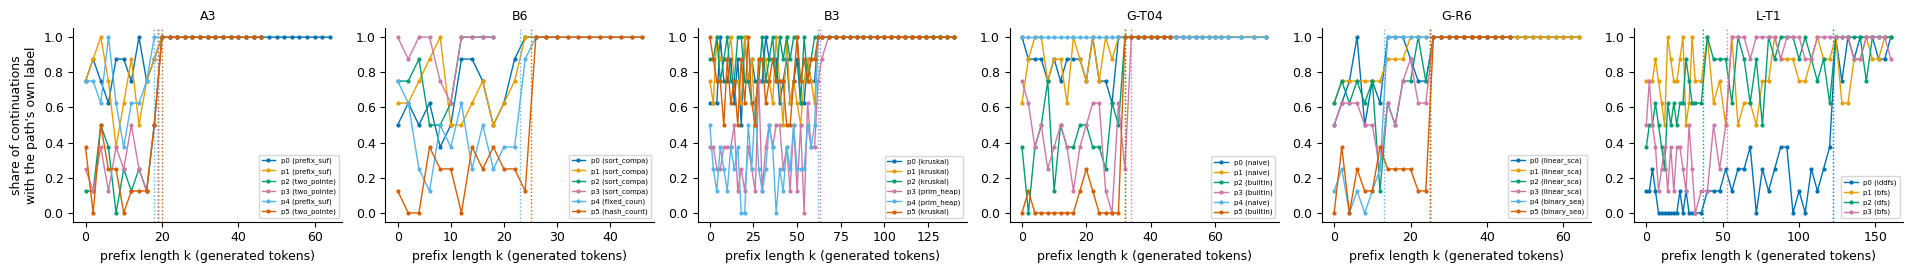

/tmp/aii_nb_test_envs/art_lzuosbrb34wB-ea92870d450a/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 24038 (\N{CJK UNIFIED IDEOGRAPH-5DE6}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


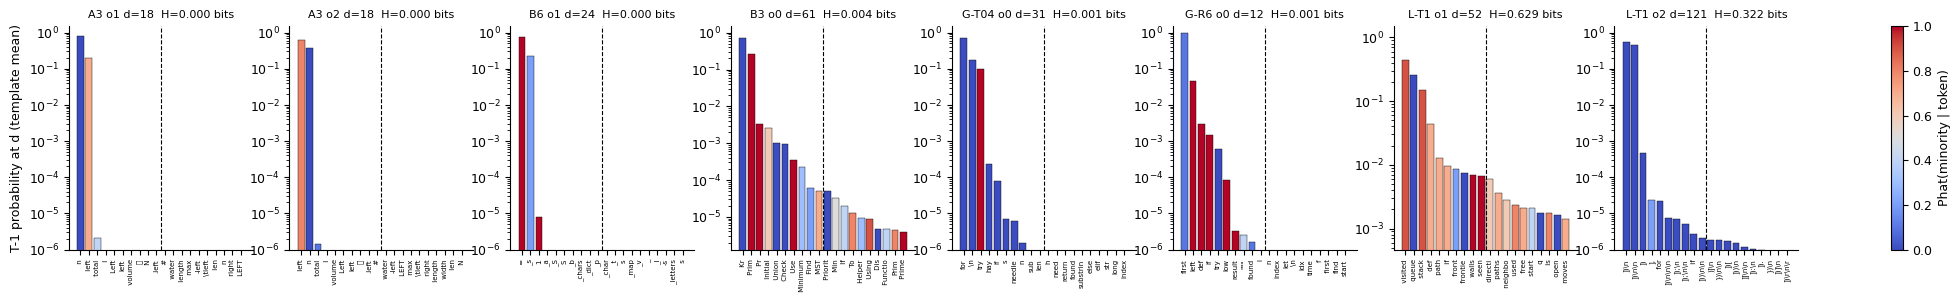

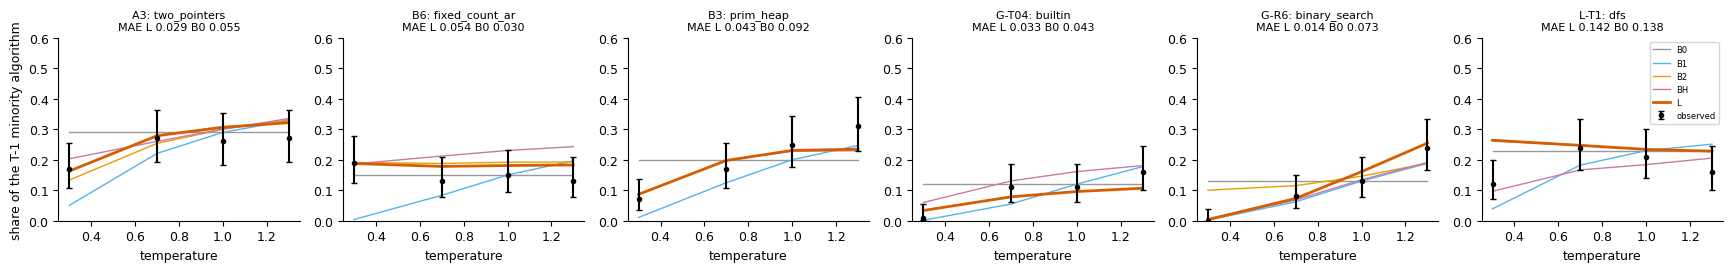

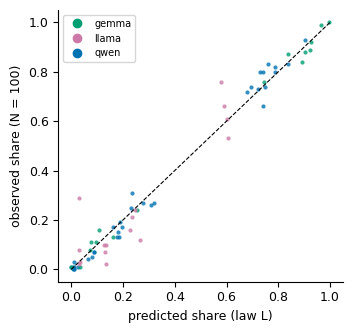

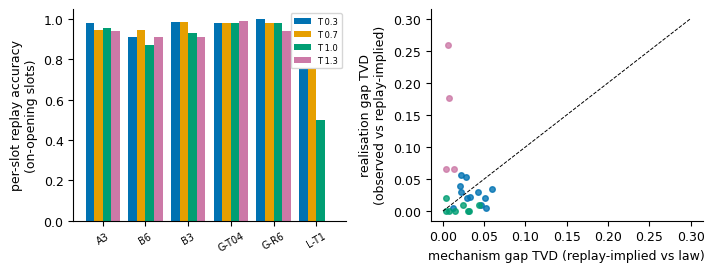

In [27]:
import figures8

figures8.LOCATE.update({u: EX[u]["locate"] for u in UNITS_TO_RUN})
figures8.f1()
figures8.f2()
figures8.f3(out)
figures8.f4(out)
figures8.f6(out)

## Summary: the whole algorithm mix per temperature, observed vs predicted
Bars show the observed share of each algorithm among the 100 top-p 1 programs at each temperature. Black lines mark the law's **predicted** cumulative shares, committed before any of these programs was sampled. When the law is right, each black line sits on the matching colour boundary.

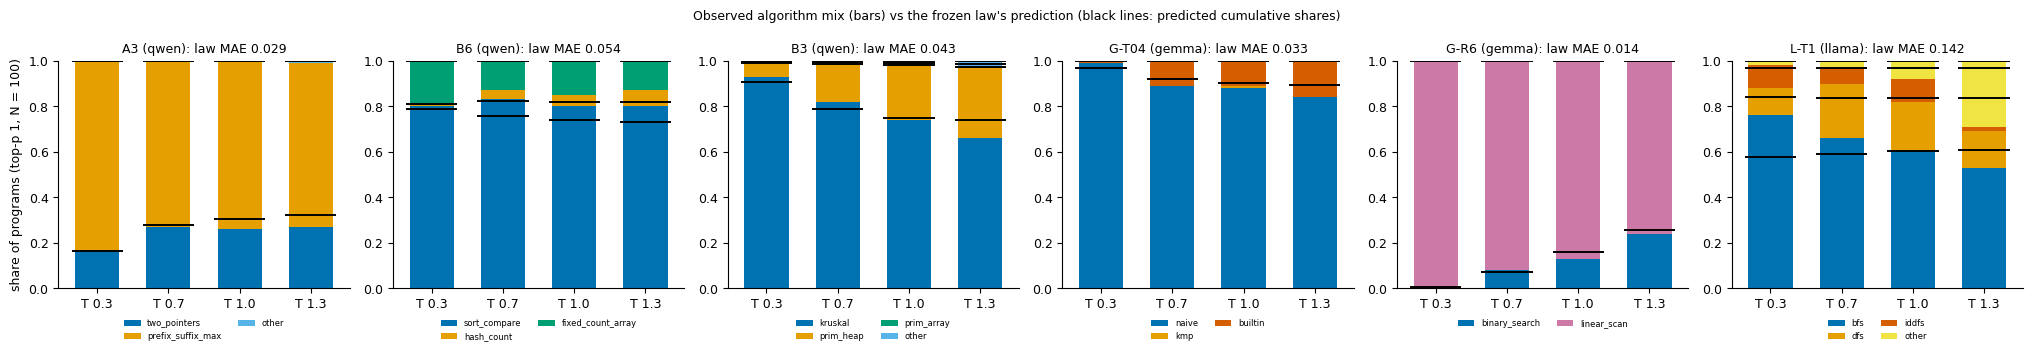

In [28]:
us = list(out["units"])
fig, axs = plt.subplots(1, len(us), figsize=(max(4.2, 3.4 * len(us)), 3.6), squeeze=False)
for ax, u in zip(axs[0], us):
    a = out["units"][u]
    x = np.arange(len(TEMPS))
    obs_cum = np.zeros(len(x))
    pred_cum = np.zeros(len(x))
    for j, b in enumerate(a["bins"]):
        obs = np.array([a["cells"][f"p1|{T}"]["shares"][j] for T in TEMPS])
        pred = np.array([a["cells"][f"p1|{T}"]["pred"]["L"][j] for T in TEMPS])
        shown = obs.max() > 0 or pred.max() >= 0.005
        ax.bar(x, obs, 0.62, bottom=obs_cum, color=figures8.PAL[j % len(figures8.PAL)], label=b if shown else None)
        obs_cum += obs
        pred_cum += pred
        if shown and j < len(a["bins"]) - 1:
            ax.hlines(pred_cum, x - 0.36, x + 0.36, colors="k", lw=1.4)
    ax.set_xticks(x, [f"T {T}" for T in TEMPS])
    ax.set_ylim(0, 1)
    ax.set_title(f"{u} ({a['family']}): law MAE {a['mae']['p1']['L']:.3f}", fontsize=9)
    ax.legend(fontsize=6, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
axs[0][0].set_ylabel("share of programs (top-p 1, N = 100)")
fig.suptitle("Observed algorithm mix (bars) vs the frozen law's prediction (black lines: predicted cumulative shares)",
             fontsize=9)
fig.tight_layout()
plt.show()

## Scaling up and reading the result
- **Configuration:** the config cell already holds the artifact's values: all six units, `N_BOOT = 1000`, `N_DROP_PLACEBO = 500`, `N_TOKEN_MAP_PLACEBO = 200`, `N_HILL1_REP = 200`, `N_H_BOOT = 300`, `U10_N = 1000`, `U11_N_U = 10000`, `CP_SELFTEST_N = 200`. The MAE table therefore reproduces `analysis_L.json`: A3 0.029, B6 0.054, B3 0.043, G-T04 0.033, G-R6 0.014, L-T1 0.142, verdict PARTIAL. The minimum values in the comments give a quicker one-unit run.
- **Regenerating the stored GPU outputs** (locator continuations, teacher forcing, sweep) needs the artifact folder: run `python method.py all` on a ≥ 20 GB GPU (about 5 h; see its `reproducibility.md`). Exact token-level reproduction also needs the same GPU class, because bf16 kernels are batch- and GPU-sensitive.
- **What it means for "creativity":** temperature is a knob over a **small, fixed repertoire**. The model's algorithm choice is concentrated in one or two decision tokens. Their teacher-forced margins predict how mass moves between known algorithms as *T* changes, and higher *T* adds phrasings, not new ideas. The law fails on Llama's grid-path task (L-T1). There the BFS/DFS decision token exists, but its openings cover only about 2% of programs, and at T 1.3 most programs degenerate.